<a href="https://colab.research.google.com/github/saulobortolon/Quaternios-Kalman-CC/blob/main/kalman/notebooks/pepe_kalman_parte2_imm.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Abrir no Colab"/></a>

*O Filtro de Kalman para Cientistas da Computação* · [← guia da série](kalman_guia_da_serie.ipynb) ([Colab](https://colab.research.google.com/github/saulobortolon/Quaternios-Kalman-CC/blob/main/kalman/notebooks/kalman_guia_da_serie.ipynb)) · [repositório](https://github.com/saulobortolon/Quaternios-Kalman-CC) · série irmã: [*Números, movimento e Kalman*](../../dominios/notebooks/X0_raiz.ipynb) ([Colab](https://colab.research.google.com/github/saulobortolon/Quaternios-Kalman-CC/blob/main/dominios/notebooks/X0_raiz.ipynb))

# Pepé Le Gambá e o Filtro de Kalman
## Parte 2: Pepé estuda Ciência da Computação e descobre as cadeias de Markov (IMM)

Na Parte 1, Pepé imaginava Penélope sempre do mesmo jeito: "ela anda com velocidade quase constante". Isso é falso. Penélope ora fica **escondida**, ora **foge** em linha reta, ora **procura um esconderijo** dando corridinhas em volta de um ponto. Na Parte 1, as fugas eram o ponto fraco de Pepé.

Agora Pepé estudou Ciência da Computação. Ele imagina que Penélope alterna entre **modos de comportamento** segundo uma **cadeia de Markov**, e mantém **um filtro de Kalman para cada modo**. A cada medida, ele faz duas perguntas ao mesmo tempo:

- **onde** ela está? (a pergunta do Kalman)
- **em que modo** ela está? (a pergunta do HMM)

Esse algoritmo chama-se **IMM** (*Interacting Multiple Model*). Ele é exatamente o encontro das duas trilhas do notebook *Duas trilhas até o Filtro de Kalman*: uma cadeia de Markov escondida comandando modelos de espaço de estados contínuos.

**Roteiro**

1. O novo mundo: os três modos de Penélope
2. Os sensores de Pepé (Fase 3, num dia de vento)
3. Como Pepé imagina cada modo: três modelos de movimento
4. A cadeia de Markov de Pepé
5. O IMM, passo a passo: misturar, prever, atualizar, pesar os modos, combinar
6. "Onde ela está" × "onde ela estará"
7. Uma perseguição completa, com os quadros explicados
8. Prever o futuro: onde o IMM realmente faz diferença
9. Comparação estatística: mundos de 2 e de 3 modos
10. Resumo e exercícios

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Ellipse, Circle

np.set_printoptions(precision=4, suppress=True)
pd.set_option("display.precision", 3)
plt.rcParams.update({"axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False})

def confere(nome, a, b, tol=1e-8):
    erro = np.max(np.abs(np.asarray(a, float) - np.asarray(b, float)))
    print(f"{'OK ' if erro < tol else 'FALHOU'}  {nome}:  diferença máxima = {erro:.2e}")
    assert erro < tol, nome

---
# 1. O novo mundo: os três modos de Penélope

Penélope agora tem três comportamentos:

| modo | o que ela faz | quando sai dele |
|---|---|---|
| **0. escondida** | fica parada | quando Pepé chega a menos da distância de gatilho: **foge** |
| **1. fugindo** | corre em **linha reta**, para longe de Pepé (com desvio aleatório), a 2,5–3,5 unidades/s, durante 3 a 5 s | no fim da fuga: começa a **procurar** esconderijo |
| **2. procurando** | dá **corridinhas** a 1,5 unidade/s entre pontos sorteados num disco de raio 2,5 em torno de onde a fuga terminou, durante 3 a 6 s | ao fim: **esconde-se**; se Pepé chegar perto: **foge** de novo |

As fugas agora são longas: de 7,5 a 17,5 unidades. Bem mais que o alcance do som ($R_{som}=6$), então **Pepé deixa de ouvir o coração** a cada fuga e precisa reencontrá-la pelo cheiro.

Há também um **mundo de 2 modos** (`MODOS_DO_MUNDO = 2`), em que ela se esconde logo após fugir, sem a fase de procura. Ele serve para comparar na seção 9.

> **Atenção: o mundo não é exatamente uma cadeia de Markov.** A fuga começa porque **Pepé chegou perto**, e não por sorteio. Pepé, porém, vai **supor** que as trocas de modo são aleatórias, com probabilidades fixas. Todo modelo é uma simplificação; o importante é ver se ela é **útil**. O exercício 2 propõe um Pepé que sabe que é ele quem a espanta.

O passo de tempo continua $\Delta t=0{,}2$ s, e cada perseguição agora dura 90 s.

In [2]:
DT, T_TOTAL = 0.2, 90.0
N_PASSOS = int(round(T_TOTAL / DT))
V_PEPE, DIST_INICIAL, BORDA = 1.0, 15.0, 40.0

ESC, FUG, PRO = 0, 1, 2
NOMES_MODOS = ["escondida", "fugindo", "procurando"]
CORES_MODOS = ["0.25", "gold", "deepskyblue"]

GATILHO      = (2.0, 4.5)     # distância de Pepé que dispara a fuga
VEL_FUGA     = (2.5, 3.5)
DUR_FUGA     = (3.0, 5.0)
DESVIO_FUGA  = 35             # graus
DUR_PROCURA  = (3.0, 6.0)
RAIO_PROCURA = 2.5
VEL_PROCURA  = 1.5

def inicia_fuga(pen, xP, rng):
    longe = np.arctan2(*(pen["p"] - xP)[::-1])
    ang = longe + rng.normal(0, np.deg2rad(DESVIO_FUGA))
    pen.update(modo=FUG, t_rest=rng.uniform(*DUR_FUGA),
               v=rng.uniform(*VEL_FUGA) * np.array([np.cos(ang), np.sin(ang)]))

def novo_ponto_de_procura(pen, rng):
    r, a = RAIO_PROCURA * np.sqrt(rng.uniform()), rng.uniform(0, 2 * np.pi)   # ponto uniforme no disco
    pen["alvo"] = pen["centro"] + r * np.array([np.cos(a), np.sin(a)])

def passo_penelope(pen, xP, rng, modos_do_mundo=3):
    perto = np.linalg.norm(xP - pen["p"]) < pen["gatilho"]
    if pen["modo"] in (ESC, PRO) and perto:
        inicia_fuga(pen, xP, rng)
    elif pen["modo"] == FUG:
        pen["t_rest"] -= DT
        if pen["t_rest"] <= 0:
            if modos_do_mundo == 3:
                pen.update(modo=PRO, t_rest=rng.uniform(*DUR_PROCURA), centro=pen["p"].copy())
                novo_ponto_de_procura(pen, rng)
            else:
                pen.update(modo=ESC, v=np.zeros(2), gatilho=rng.uniform(*GATILHO))
    elif pen["modo"] == PRO:
        pen["t_rest"] -= DT
        if pen["t_rest"] <= 0:
            pen.update(modo=ESC, v=np.zeros(2), gatilho=rng.uniform(*GATILHO))
        else:
            d = pen["alvo"] - pen["p"]
            if np.linalg.norm(d) < VEL_PROCURA * DT:            # chegou ao ponto: sorteia outro
                novo_ponto_de_procura(pen, rng); d = pen["alvo"] - pen["p"]
            pen["v"] = VEL_PROCURA * d / np.linalg.norm(d)
    pen["p"] = pen["p"] + pen["v"] * DT
    for k in range(2):
        if abs(pen["p"][k]) > BORDA:
            pen["p"][k] = np.sign(pen["p"][k]) * BORDA; pen["v"][k] *= -1
    return pen

Algumas linhas merecem explicação:

- **`r = RAIO_PROCURA * np.sqrt(rng.uniform())`**: para sortear um ponto **uniforme** num disco, o raio tem de ser a **raiz** de um uniforme. Se usássemos o uniforme direto, os pontos se concentrariam perto do centro, porque há menos área perto do centro que na borda.
- **`if np.linalg.norm(d) < VEL_PROCURA * DT`**: se o próximo passo já a levaria além do ponto-alvo, ela "chegou", e sorteamos outro. São as corridinhas.
- **`pen["modo"] in (ESC, PRO) and perto`**: tanto escondida quanto procurando, ela foge se Pepé chegar perto.

---
# 2. Os sensores de Pepé: Fase 3, num dia de vento

Os sensores são os da Fase 3 da Parte 1: gradiente e intensidade do cheiro sempre, e gradiente e intensidade do som quando ele está a menos de $R_{som}$. A única mudança é que hoje **venta mais**: os ruídos do cheiro dobram ou mais ($\sigma_w=0{,}02$, $\sigma_I=0{,}05$). Com sensores perfeitos, qualquer modelo de movimento funcionaria; o vento torna o **modelo** importante.

As funções e os jacobianos são os mesmos da Parte 1 (lá conferidos pelo passo complexo).

In [3]:
A_C, SIG_C = 1.0, 6.0
B_S, EPS_S, R_SOM = 1.0, 1.0, 6.0
SIG_W, SIG_I, SIG_SG, SIG_SI = 0.02, 0.05, 0.002, 0.003

def cheiro(x, p):
    d = x - p; return A_C * np.exp(-(d @ d) / (2 * SIG_C**2))
def grad_cheiro(x, p):
    return -cheiro(x, p) / SIG_C**2 * (x - p)
def som(x, p):
    d = x - p; return B_S / (d @ d + EPS_S**2)
def grad_som(x, p):
    d = x - p; return -2 * B_S * d / (d @ d + EPS_S**2)**2

def mede(xP, p, rng):
    z = [grad_cheiro(xP, p) + SIG_W * rng.standard_normal(2), [cheiro(xP, p) + SIG_I * rng.standard_normal()]]
    var = [SIG_W**2, SIG_W**2, SIG_I**2]
    ouviu = np.linalg.norm(xP - p) < R_SOM
    if ouviu:
        z += [grad_som(xP, p) + SIG_SG * rng.standard_normal(2), [som(xP, p) + SIG_SI * rng.standard_normal()]]
        var += [SIG_SG**2, SIG_SG**2, SIG_SI**2]
    return np.concatenate(z), np.diag(var), ouviu

def h_modelo(s, xP, ouviu):
    p = s[:2]; partes = [grad_cheiro(xP, p), [cheiro(xP, p)]]
    if ouviu: partes += [grad_som(xP, p), [som(xP, p)]]
    return np.concatenate(partes)

def J_modelo(s, xP, ouviu):
    p = s[:2]; d = xP - p; c = cheiro(xP, p)
    linhas = [c / SIG_C**2 * (np.eye(2) - np.outer(d, d) / SIG_C**2), (c * d / SIG_C**2)[None, :]]
    if ouviu:
        D = d @ d + EPS_S**2
        linhas += [2 * B_S / D**2 * (np.eye(2) - 4 * np.outer(d, d) / D), (2 * B_S * d / D**2)[None, :]]
    Jp = np.vstack(linhas)
    return np.hstack([Jp, np.zeros_like(Jp)])

---
# 3. Como Pepé imagina cada modo: três modelos de movimento

O estado continua sendo $s=(p_1,p_2,v_1,v_2)$. Para cada modo $j$, Pepé tem um par $(F_j, Q_j)$ que descreve como ele **imagina** que Penélope se move naquele modo.

**Modo 0, escondida: "parada, mas pronta para arrancar".**

$$F_0=\begin{bmatrix}I & 0\\ 0 & 0\end{bmatrix},\qquad Q_0=\begin{bmatrix}q_p\,\Delta t\, I & 0\\ 0 & \sigma_v^2 I\end{bmatrix}.$$

A posição não muda (só um ruído minúsculo $q_p$). A velocidade é **zerada** e substituída por um ruído largo, $\sigma_v^2=4$. Isso parece estranho, mas tem um papel importante. A velocidade não afeta a posição neste modo (o bloco superior direito de $F_0$ é zero), então esse ruído não atrapalha a estimativa de onde ela está escondida. Ele significa "não sei com que velocidade ela vai arrancar". Quando o IMM passa esse estado para o filtro do modo "fugindo" (a **mistura**, seção 5), o filtro recebe uma velocidade inicial **com incerteza grande**, e consegue se ajustar à fuga em poucos passos.

**Modo 1, fugindo: velocidade constante.** É o modelo da Parte 1, com uma "humildade" pequena ($q=0{,}5$): ela corre em linha reta.

**Modo 2, procurando: velocidade que se renova.**

$$v_{t+1}=a\,v_t+w_t,\quad a=0{,}6,\qquad p_{t+1}=p_t+\Delta t\,v_t .$$

A velocidade "esquece" o passado ($a<1$) e recebe impulsos aleatórios grandes. O resultado são corridinhas curtas em direções que mudam, sem se afastar muito. Esse é o **modelo de Singer**, clássico para alvos que manobram.

A figura mostra cinco trajetórias que **cada modelo imagina**, partindo da origem com velocidade (2, 0), durante 3 s. É um jeito de ver o que cada par $(F_j,Q_j)$ "acredita".

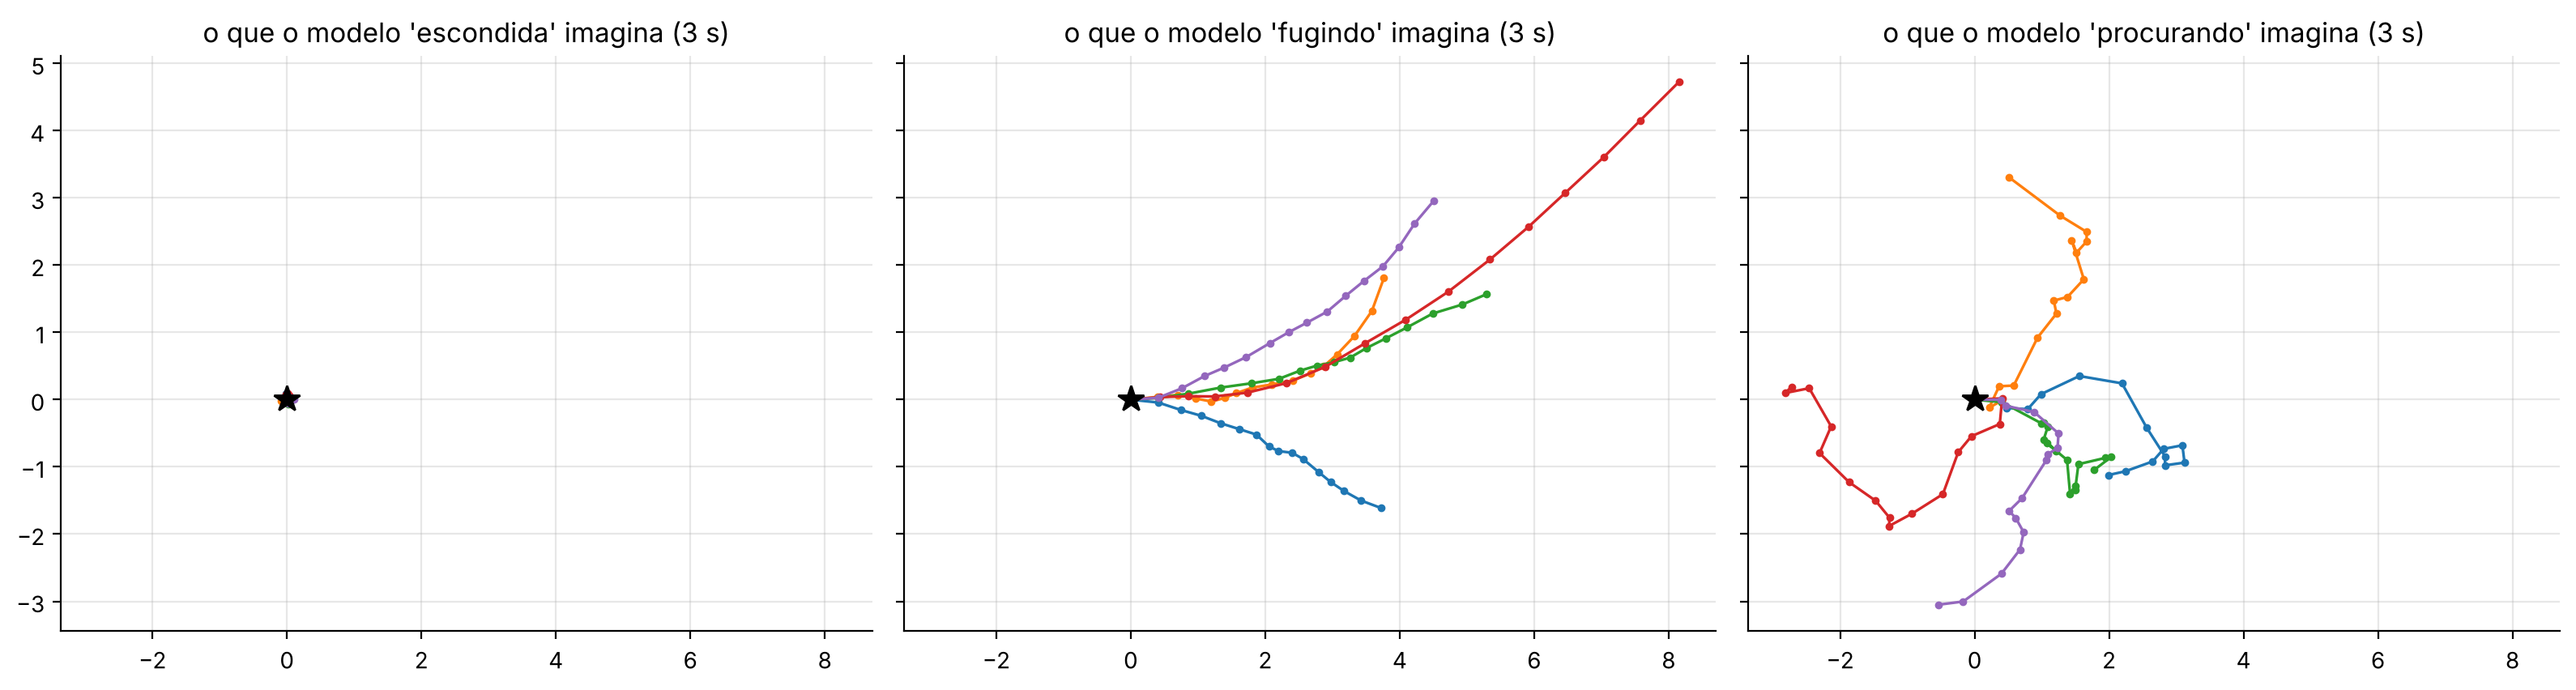

In [4]:
I2, Z2 = np.eye(2), np.zeros((2, 2))

def modelo_escondida(qp=1e-3, var_v=4.0):
    return np.block([[I2, Z2], [Z2, Z2]]), np.block([[qp * DT * I2, Z2], [Z2, var_v * I2]])

def modelo_fugindo(q=0.5):
    F = np.block([[I2, DT * I2], [Z2, I2]])
    Q = q * np.block([[DT**3 / 3 * I2, DT**2 / 2 * I2], [DT**2 / 2 * I2, DT * I2]])
    return F, Q

def modelo_procurando(a=0.6, var_v=1.5):
    return np.block([[I2, DT * I2], [Z2, a * I2]]), np.block([[1e-3 * I2, Z2], [Z2, var_v * I2]])

def modelo_unico(q=1.0):           # o Pepé da Parte 1: um só modelo, velocidade quase constante
    return modelo_fugindo(q)

rng_demo = np.random.default_rng(3)
fig, ax = plt.subplots(1, 3, figsize=(16, 4.5), sharex=True, sharey=True)
for a, (nome, (Fm, Qm)) in zip(ax, [("escondida", modelo_escondida()), ("fugindo", modelo_fugindo()),
                                    ("procurando", modelo_procurando())]):
    L = np.linalg.cholesky(Qm + 1e-12 * np.eye(4))
    for _ in range(5):
        s = np.array([0.0, 0.0, 2.0, 0.0]); traj = [s[:2]]
        for _ in range(15):
            s = Fm @ s + L @ rng_demo.standard_normal(4); traj.append(s[:2])
        a.plot(*np.array(traj).T, "o-", ms=2.5, lw=1.2)
    a.plot(0, 0, "k*", ms=12); a.set_title(f"o que o modelo '{nome}' imagina (3 s)"); a.set_aspect("equal")
plt.tight_layout(); plt.show()

**O que observar.** "Escondida" não sai do lugar (a velocidade inicial é ignorada). "Fugindo" segue em linha quase reta. "Procurando" dá voltas curtas e erráticas, sem ir longe.

Para gerar ruído com covariância $Q$, usamos `np.linalg.cholesky(Q)`: se $Q=LL^\top$ e $\varepsilon\sim\mathcal N(0,I)$, então $L\varepsilon\sim\mathcal N(0,Q)$. O `1e-12 * np.eye(4)` evita erro numérico quando $Q$ tem autovalores quase nulos.

---
# 4. A cadeia de Markov de Pepé

Pepé supõe que, a cada passo, Penélope troca de modo com probabilidades fixas $\Pi_{ij}=P(\text{modo } j \text{ agora}\mid \text{modo } i \text{ antes})$. Como escolher esses números? Por **durações médias**.

Se a probabilidade de **ficar** no modo $i$ em cada passo é $\Pi_{ii}$, o tempo de permanência segue uma distribuição **geométrica**, com média $\Delta t/(1-\Pi_{ii})$. Invertendo:

$$\Pi_{ii}=1-\frac{\Delta t}{d_i},$$

onde $d_i$ é a duração média que Pepé imagina para o modo $i$. A probabilidade restante, $\Delta t/d_i$, é dividida entre os destinos possíveis.

| modo | duração média imaginada | para onde vai ao sair |
|---|---|---|
| escondida | 6 s | fugindo |
| fugindo | 4 s | procurando (no modelo de 2 modos: escondida) |
| procurando | 4,5 s | 80% escondida, 20% fugindo |

É o mesmo tipo de matriz do passeio do bêbado do notebook de HMM, só que agora os "estados" são **comportamentos**, e não posições. A duração geométrica é a limitação conhecida do HMM, mencionada no primeiro notebook: modos com durações mais regulares pediriam um modelo semi-Markov.

In [5]:
def matriz_de_transicao(duracoes, destinos):
    M = len(duracoes); Pi = np.zeros((M, M))
    for i, (d, dest) in enumerate(zip(duracoes, destinos)):
        Pi[i, i] = 1 - DT / d
        for j, w in dest.items():
            Pi[i, j] += (DT / d) * w
    return Pi

PEPE = {
    "modelo único (Parte 1)": dict(modelos=[modelo_unico()], Pi=np.ones((1, 1)), mu0=[1.0]),
    "IMM de 2 modos": dict(modelos=[modelo_escondida(), modelo_fugindo()],
                           Pi=matriz_de_transicao([6.0, 4.0], [{1: 1.0}, {0: 1.0}]), mu0=[0.9, 0.1]),
    "IMM de 3 modos": dict(modelos=[modelo_escondida(), modelo_fugindo(), modelo_procurando()],
                           Pi=matriz_de_transicao([6.0, 4.0, 4.5], [{1: 1.0}, {2: 1.0}, {0: 0.8, 1: 0.2}]),
                           mu0=[0.8, 0.1, 0.1]),
}
Pi3 = PEPE["IMM de 3 modos"]["Pi"]
print("Matriz de transição do IMM de 3 modos (linhas: de; colunas: para):")
print(pd.DataFrame(Pi3, index=NOMES_MODOS, columns=NOMES_MODOS).round(4).to_string())
confere("as linhas de Π somam 1", Pi3.sum(1), np.ones(3), tol=1e-12)
w_, V_ = np.linalg.eig(Pi3.T); est = np.real(V_[:, np.argmin(abs(w_ - 1))]); est /= est.sum()
print("\nfração do tempo em cada modo, a longo prazo (distribuição estacionária):", dict(zip(NOMES_MODOS, est.round(3))))

Matriz de transição do IMM de 3 modos (linhas: de; colunas: para):
            escondida  fugindo  procurando
escondida       0.967    0.033       0.000
fugindo         0.000    0.950       0.050
procurando      0.036    0.009       0.956
OK   as linhas de Π somam 1:  diferença máxima = 0.00e+00

fração do tempo em cada modo, a longo prazo (distribuição estacionária): {'escondida': np.float64(0.361), 'fugindo': np.float64(0.301), 'procurando': np.float64(0.338)}


---
# 5. O IMM, passo a passo

O IMM mantém, para cada modo $j$:
- a média $m_j$ e a covariância $P_j$ de um filtro de Kalman que **supõe** que ela está no modo $j$;
- a probabilidade $\mu_j$ de ela estar **de fato** no modo $j$.

A cada nova medida, são cinco etapas.

**(1) Mistura.** Antes de prever, cada filtro recomeça de uma **média ponderada** dos filtros, com pesos dados pela chance de ter vindo de cada modo. A probabilidade de estar no modo $j$ **antes** da medida é

$$c_j=\sum_i \Pi_{ij}\,\mu_i ,$$

e a probabilidade de ter **vindo** do modo $i$, sabendo que agora está em $j$, é

$$\mu_{i|j}=\frac{\Pi_{ij}\,\mu_i}{c_j}.$$

Com esses pesos, a média e a covariância de partida do filtro $j$ são

$$m^0_j=\sum_i\mu_{i|j}\,m_i,\qquad P^0_j=\sum_i \mu_{i|j}\Big[P_i+(m_i-m^0_j)(m_i-m^0_j)^\top\Big].$$

O segundo termo de $P^0_j$ **soma a discordância** entre os filtros. Se eles discordam, a incerteza de partida cresce. É por isso que o filtro "fugindo" consegue arrancar: ele herda a velocidade incerta do filtro "escondida".

**(2) Previsão por modo.** Cada filtro prevê com o **seu** modelo: $m_j^-=F_jm^0_j$ e $P_j^-=F_jP^0_jF_j^\top+Q_j$.

**(3) Atualização por modo.** Cada filtro incorpora a medida $z$ com o Kalman iterado (como na Parte 1, com até 5 iterações). Cada um também calcula a **verossimilhança** $L_j=\mathcal N(v_j;0,S_j)$: quão plausível era essa medida **se** ela estivesse no modo $j$. Para o Kalman iterado, a inovação $v_j$ e a covariância $S_j$ são calculadas com a linearização do ponto final da iteração.

**(4) Probabilidades dos modos: o *forward* do HMM.**

$$\mu_j\ \propto\ \underbrace{c_j}_{\text{predição pela cadeia}}\ \times\ \underbrace{L_j}_{\text{"emissão"}} .$$

Compare com o *forward* do notebook de HMM: $\alpha_t\propto(\alpha_{t-1}\Pi)\odot B_{:,y_t}$. É **a mesma conta**. O papel da probabilidade de emissão $B_{j,y}$ é desempenhado pela verossimilhança do filtro $j$.

**(5) Combinação.** Para decidir para onde andar, Pepé resume tudo numa só crença:

$$m=\sum_j\mu_j m_j,\qquad P=\sum_j\mu_j\Big[P_j+(m_j-m)(m_j-m)^\top\Big].$$

In [6]:
def atualizacao_iterada(m, P, z, R, h, J, n_iter=5, tol=1e-9):
    # Kalman iterado (Bell & Cathey). Devolve também a log-verossimilhança da medida.
    s = m.copy()
    for _ in range(n_iter):
        H = J(s); S = H @ P @ H.T + R; K = np.linalg.solve(S, H @ P).T
        s_novo = m + K @ (z - h(s) - H @ (m - s))
        if np.linalg.norm(s_novo - s) < tol: s = s_novo; break
        s = s_novo
    H = J(s); S = H @ P @ H.T + R; K = np.linalg.solve(S, H @ P).T
    v = z - h(s) - H @ (m - s)                                   # inovação, linearizada no ponto final
    ll = -0.5 * (v @ np.linalg.solve(S, v) + np.linalg.slogdet(2 * np.pi * S)[1])
    P_novo = P - K @ S @ K.T
    return s, (P_novo + P_novo.T) / 2, ll

def mistura(mu, ms, Ps, Pi):                                      # etapa (1)
    c = mu @ Pi                                                   # c_j = Σ_i Π_ij μ_i
    W = (Pi * mu[:, None]) / c[None, :]                           # W[i, j] = μ_{i|j}
    m0, P0 = [], []
    for j in range(len(mu)):
        mj = sum(W[i, j] * ms[i] for i in range(len(mu)))
        Pj = sum(W[i, j] * (Ps[i] + np.outer(ms[i] - mj, ms[i] - mj)) for i in range(len(mu)))
        m0.append(mj); P0.append(Pj)
    return c, W, m0, P0

def preve_por_modo(modelos, m0, P0):                               # etapa (2)
    return [F @ m for (F, Q), m in zip(modelos, m0)], [F @ P @ F.T + Q for (F, Q), P in zip(modelos, P0)]

def combina(mu, ms, Ps):                                          # etapa (5)
    m = sum(w * x for w, x in zip(mu, ms))
    P = sum(w * (Pj + np.outer(x - m, x - m)) for w, x, Pj in zip(mu, ms, Ps))
    return m, P

Alguns detalhes do código:

- **`W = (Pi * mu[:, None]) / c[None, :]`** calcula todos os $\mu_{i|j}$ de uma vez. `mu[:, None]` transforma o vetor $\mu$ numa **coluna**, então `Pi * mu[:, None]` multiplica a linha $i$ de $\Pi$ por $\mu_i$. Dividir por `c[None, :]` (uma **linha**) normaliza cada coluna $j$. É o *broadcasting* do NumPy.
- **Piso de probabilidade.** No laço principal, depois da etapa (4), nenhuma $\mu_j$ fica abaixo de $10^{-12}$. Sem isso, um modo pode chegar a probabilidade **exatamente** zero por *underflow*. Se isso acontecer com todos os modos que alimentam um modo $j$, o $c_j$ da mistura vira zero e a divisão $\Pi_{ij}\mu_i/c_j$ produz `NaN`. Na prática, o piso diz: "nunca descarte uma hipótese por completo".
- **Por que a etapa (4) não aparece aqui?** Ela fica dentro do laço principal, porque precisa das verossimilhanças de todos os filtros. Para evitar *underflow* (verossimilhanças como $e^{-800}$), ela trabalha com logaritmos: subtrai o maior antes de exponenciar, `np.exp(lls - lls.max())`. O fator comum se cancela na normalização.

Três conferências:

1. **A mistura preserva a média global** (lei da esperança total): $\sum_j c_j\,m^0_j=\sum_i\mu_i\,m_i$.
2. **As colunas de $W$ somam 1**: cada filtro recebe uma mistura de verdade.
3. **A combinação de um só filtro devolve o próprio filtro.**

In [7]:
rng_t = np.random.default_rng(0)
mu_t = np.array([0.6, 0.3, 0.1])
ms_t = [rng_t.normal(size=4) for _ in range(3)]
Ps_t = [np.diag(rng_t.uniform(0.5, 2, 4)) for _ in range(3)]
c_t, W_t, m0_t, P0_t = mistura(mu_t, ms_t, Ps_t, Pi3)
confere("mistura preserva a média global", sum(c * m for c, m in zip(c_t, m0_t)), sum(u * m for u, m in zip(mu_t, ms_t)), tol=1e-12)
confere("colunas de W (μ_{i|j}) somam 1", W_t.sum(0), np.ones(3), tol=1e-12)
mc_, Pc_ = combina(np.array([1.0]), [ms_t[0]], [Ps_t[0]])
confere("combinar um só filtro devolve o próprio filtro", np.r_[mc_, Pc_.ravel()], np.r_[ms_t[0], Ps_t[0].ravel()], tol=1e-15)

OK   mistura preserva a média global:  diferença máxima = 1.11e-16
OK   colunas de W (μ_{i|j}) somam 1:  diferença máxima = 1.11e-16
OK   combinar um só filtro devolve o próprio filtro:  diferença máxima = 0.00e+00


---
# 6. "Onde ela está" × "onde ela estará"

Na Parte 1, Pepé andava para a posição estimada **agora**. Mas Pepé leva tempo para chegar. Se ele está a uma distância $d$ da estimativa, levará $\tau=d/V_{Pepé}$ segundos. Um Pepé esperto mira onde ela **estará** daqui a $\tau$.

Como "imaginar" o futuro? Rodando as etapas (1) e (2) do IMM **sem medidas**, $n=\tau/\Delta t$ vezes. A cadeia de Markov entra aqui de um jeito essencial:
- um modelo único extrapola a fuga em linha reta **para sempre**;
- o IMM "sabe" que fugas acabam: a cada passo imaginado, parte da probabilidade migra para "procurando" e "escondida", modos em que ela para.

Limitamos o horizonte a $\tau_{máx}=4$ s, porque previsões muito longas ficam vagas demais.

In [8]:
TAU_MAX = 4.0

def preve_adiante(mu, ms, Ps, modelos, Pi, n):
    # Imagina n passos à frente: mistura + previsão, sem medidas. Devolve a posição combinada.
    for _ in range(n):
        c, _, m0, P0 = mistura(mu, ms, Ps, Pi)
        ms, Ps = preve_por_modo(modelos, m0, P0)
        mu = c                                                     # sem medida, μ só evolui pela cadeia
    return combina(mu, ms, Ps)[0][:2], mu

# conferência: com n = 0, a "previsão" é a própria estimativa combinada
confere("prever 0 passos = estimativa atual", preve_adiante(mu_t, ms_t, Ps_t, PEPE["IMM de 3 modos"]["modelos"], Pi3, 0)[0],
        combina(mu_t, ms_t, Ps_t)[0][:2], tol=1e-15)

OK   prever 0 passos = estimativa atual:  diferença máxima = 0.00e+00


### O laço da perseguição

A função `simula` junta tudo. Ela serve para qualquer Pepé do dicionário `PEPE`: com um só modelo, o IMM se reduz exatamente ao Kalman iterado da Parte 1 (conferido logo abaixo). Para cada passo, ela guarda tudo o que é preciso para os gráficos e os quadros.

In [9]:
def simula(pepe, alvo="esta", seed=0, modos_do_mundo=3, n_iter=5, guarda_filtros=False):
    modelos, Pi, mu = pepe["modelos"], pepe["Pi"], np.array(pepe["mu0"], float)
    M = len(modelos)
    rng = np.random.default_rng(seed); ang0 = rng.uniform(0, 2 * np.pi)
    pen = dict(p=DIST_INICIAL * np.array([np.cos(ang0), np.sin(ang0)]), v=np.zeros(2), modo=ESC,
               t_rest=0.0, gatilho=rng.uniform(*GATILHO))
    xP = np.zeros(2)
    ms = [np.zeros(4) for _ in range(M)]; Ps = [np.diag([64.0, 64.0, 1.0, 1.0]) for _ in range(M)]
    reg = []
    for k in range(N_PASSOS):
        pen = passo_penelope(pen, xP, rng, modos_do_mundo)
        z, R, ouviu = mede(xP, pen["p"], rng)
        if k > 0:
            c, W, m0, P0 = mistura(mu, ms, Ps, Pi)                       # (1)
            ms, Ps = preve_por_modo(modelos, m0, P0)                     # (2)
        else:
            c, W = mu.copy(), np.eye(M)
        ms_pred = [x.copy() for x in ms]
        lls = np.zeros(M)
        for j in range(M):                                              # (3)
            ms[j], Ps[j], lls[j] = atualizacao_iterada(ms[j], Ps[j], z, R, lambda s: h_modelo(s, xP, ouviu),
                                                       lambda s: J_modelo(s, xP, ouviu), n_iter)
        w = c * np.exp(lls - lls.max()); mu = w / w.sum()               # (4) forward do HMM
        mu = np.maximum(mu, 1e-12); mu /= mu.sum()                      # nenhum modo fica com probabilidade exatamente zero
        m, P = combina(mu, ms, Ps)                                      # (5)
        if alvo == "estara":
            n = int(round(min(np.linalg.norm(m[:2] - xP) / V_PEPE, TAU_MAX) / DT))
            destino = preve_adiante(mu, ms, Ps, modelos, Pi, n)[0] if n > 0 else m[:2]
        else:
            destino = m[:2]
        r = dict(t=k * DT, xP=xP.copy(), p=pen["p"].copy(), modo=pen["modo"], ouviu=ouviu, z=z,
                 c=c, W=W, lls=lls, mu=mu.copy(), m=m.copy(), P=P.copy(), destino=destino.copy())
        if guarda_filtros:
            r.update(ms=[x.copy() for x in ms], Ps=[x.copy() for x in Ps], ms_pred=ms_pred)
        reg.append(r)
        d = destino - xP
        if np.linalg.norm(d) > 1e-9:
            xP = xP + V_PEPE * DT * d / np.linalg.norm(d)
    return reg

def series(reg):
    out = {k: np.array([r[k] for r in reg]) for k in ["t", "modo", "ouviu"]}
    out["mu"] = np.array([r["mu"] for r in reg])
    out["erro"] = np.array([np.linalg.norm(r["m"][:2] - r["p"]) for r in reg])
    out["sd"] = np.array([np.sqrt(np.trace(r["P"][:2, :2])) for r in reg])
    out["dist"] = np.array([np.linalg.norm(r["xP"] - r["p"]) for r in reg])
    out["nees"] = np.array([(r["m"][:2] - r["p"]) @ np.linalg.solve(r["P"][:2, :2], r["m"][:2] - r["p"]) for r in reg])
    return out

**Conferência: IMM com um modo = Kalman iterado da Parte 1.** Com um só modelo, $\Pi=[1]$, a mistura não faz nada, $\mu$ fica sempre 1 e a combinação devolve o próprio filtro. Escrevemos o laço do Kalman iterado "à mão", com as mesmas medidas, e comparamos.

In [10]:
reg_u = simula(PEPE["modelo único (Parte 1)"], seed=11)
F1, Q1 = modelo_unico()
m, P = np.zeros(4), np.diag([64.0, 64.0, 1.0, 1.0]); difs = []
for k, r in enumerate(reg_u):
    if k > 0: m, P = F1 @ m, F1 @ P @ F1.T + Q1
    R_ = np.diag([SIG_W**2, SIG_W**2, SIG_I**2] + ([SIG_SG**2, SIG_SG**2, SIG_SI**2] if r["ouviu"] else []))
    m, P, _ = atualizacao_iterada(m, P, r["z"], R_, lambda s: h_modelo(s, r["xP"], r["ouviu"]),
                                  lambda s: J_modelo(s, r["xP"], r["ouviu"]))
    difs.append(np.max(np.abs(m - r["m"])))
confere(f"IMM com 1 modo = Kalman iterado comum ({len(reg_u)} passos)", max(difs), 0, tol=1e-9)

OK   IMM com 1 modo = Kalman iterado comum (450 passos):  diferença máxima = 0.00e+00


---
# 7. Uma perseguição completa

Agora o Pepé completo: **IMM de 3 modos, mirando onde ela estará**, no mundo de 3 modos. A primeira figura resume os 90 s:

- **à esquerda**, os caminhos, com a trajetória de Penélope colorida pelo modo **verdadeiro**;
- **à direita, em cima**, as probabilidades de modo que Pepé calcula, $\mu_t$, empilhadas, com o modo verdadeiro numa faixa fina acima;
- **à direita, embaixo**, o erro da estimativa e a incerteza declarada.

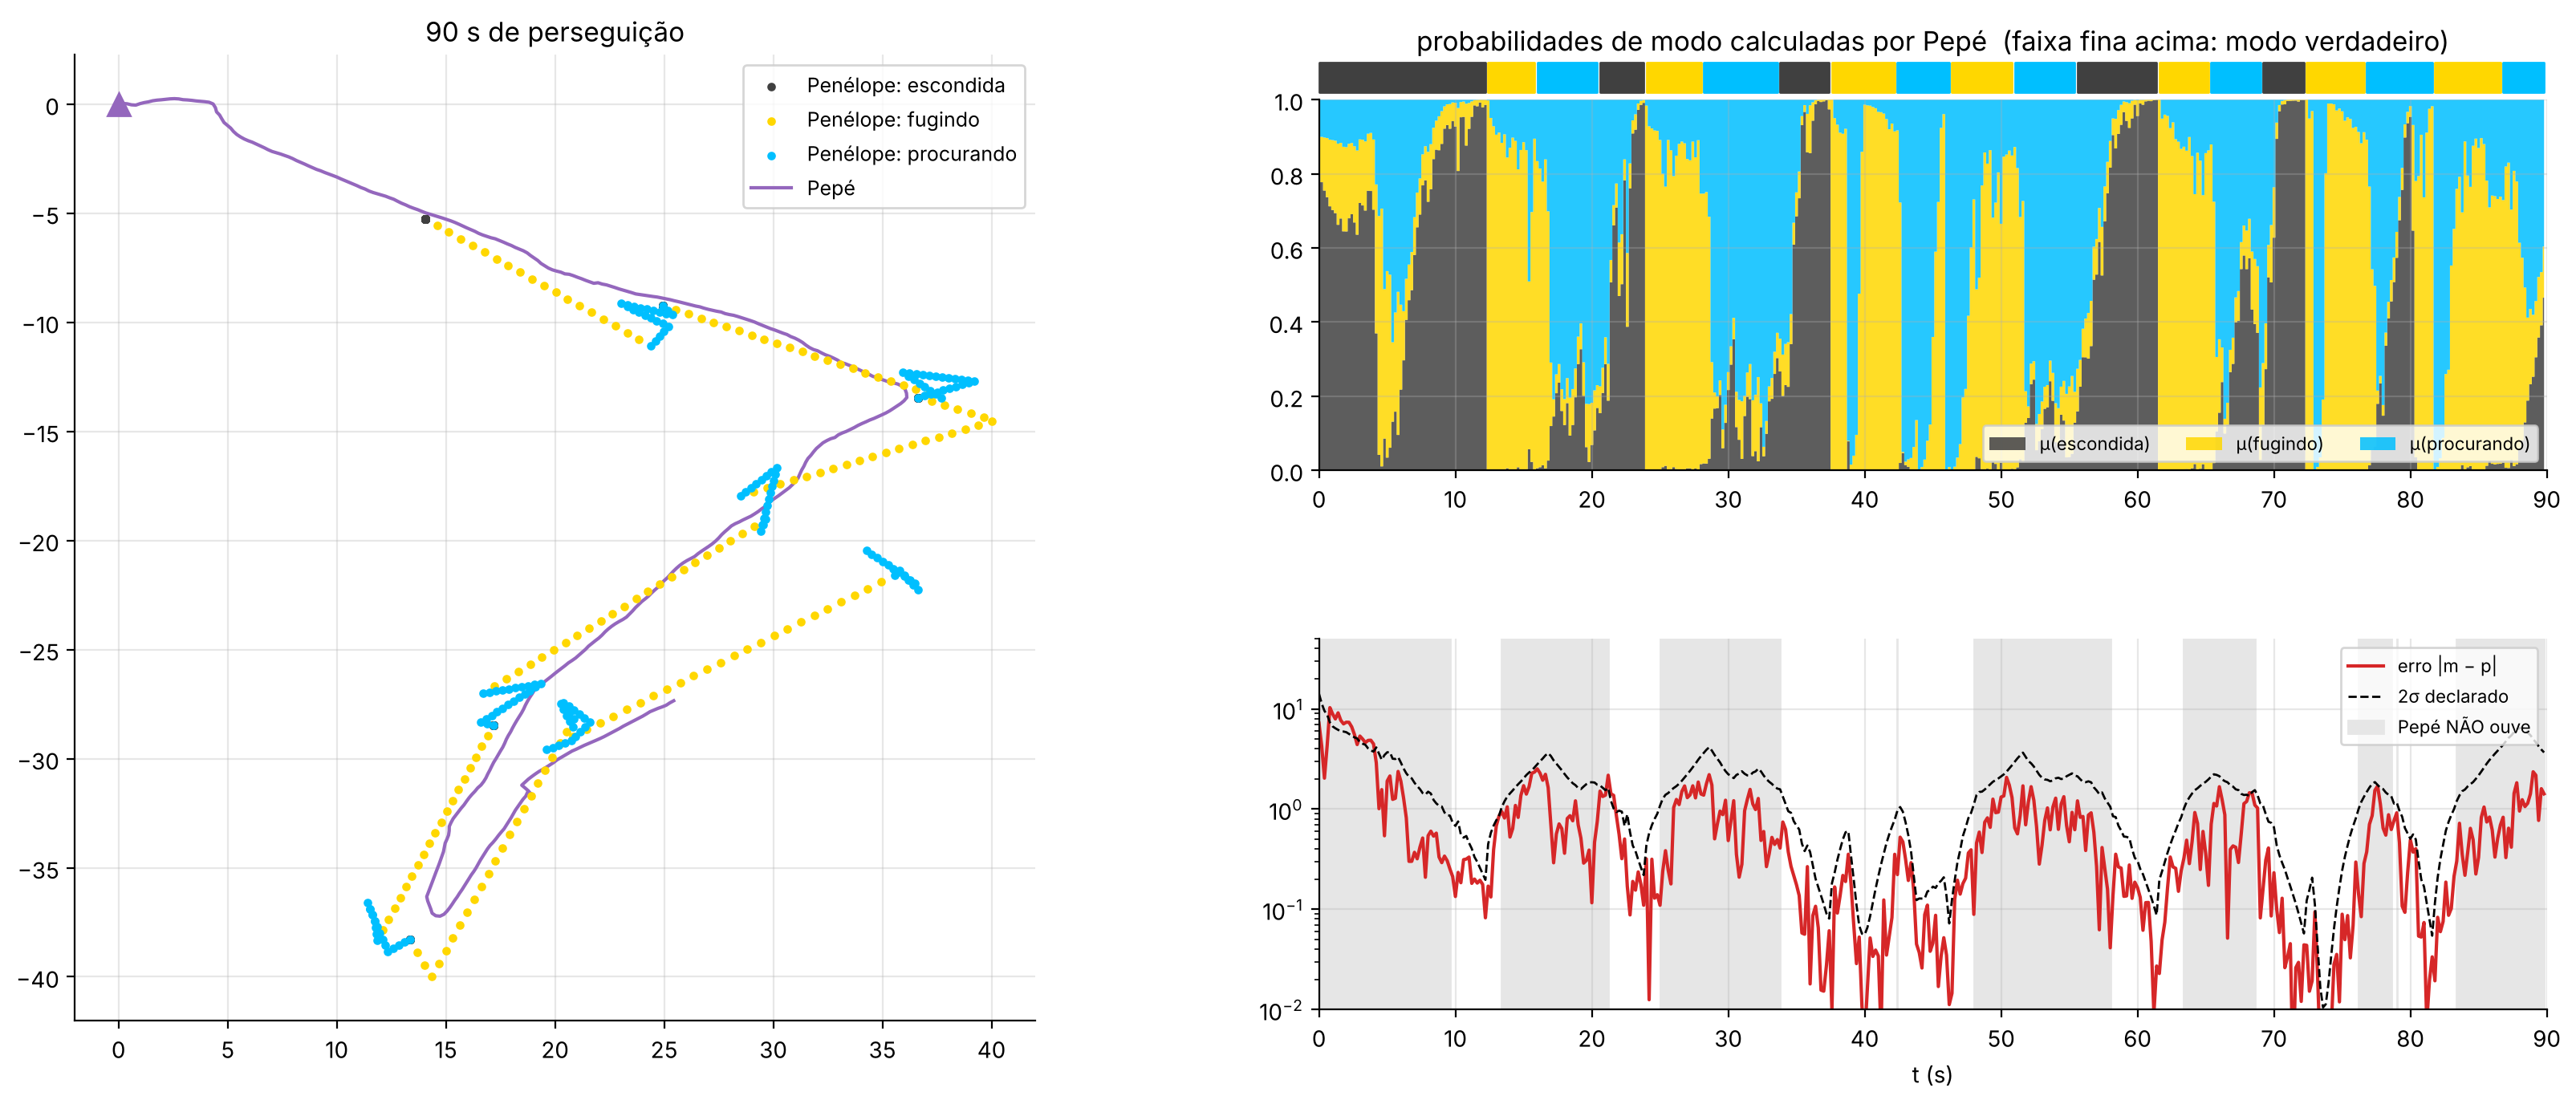

Pepé acerta o modo (o mais provável = o verdadeiro) em 76% do tempo


In [11]:
SEED = 4
reg = simula(PEPE["IMM de 3 modos"], alvo="estara", seed=SEED, guarda_filtros=True)
S = series(reg)

def faixa_modos(ax, S_, ate=None):
    ate = len(S_["t"]) if ate is None else ate
    for j in range(3):
        ax.fill_between(S_["t"][:ate], 1.02, 1.10, where=S_["modo"][:ate] == j, color=CORES_MODOS[j], step="mid",
                        transform=ax.get_xaxis_transform(), clip_on=False)

fig = plt.figure(figsize=(17, 7))
axA = fig.add_axes([0.03, 0.07, 0.42, 0.86]); axM = fig.add_axes([0.52, 0.56, 0.45, 0.33]); axE = fig.add_axes([0.52, 0.08, 0.45, 0.33])
cam = np.array([r["p"] for r in reg]); camP = np.array([r["xP"] for r in reg])
for j in range(3):
    sel = S["modo"] == j
    axA.scatter(*cam[sel].T, s=8, color=CORES_MODOS[j], label=f"Penélope: {NOMES_MODOS[j]}", zorder=3)
axA.plot(*camP.T, color="C4", lw=1.5, label="Pepé"); axA.plot(0, 0, "^", color="C4", ms=10)
axA.set_aspect("equal"); axA.legend(fontsize=9); axA.set_title("90 s de perseguição")
axM.stackplot(S["t"], S["mu"].T, colors=CORES_MODOS, labels=[f"μ({n})" for n in NOMES_MODOS], alpha=.85, step="mid")
faixa_modos(axM, S); axM.set_ylim(0, 1); axM.set_xlim(0, T_TOTAL); axM.legend(loc="lower right", fontsize=8, ncol=3)
axM.set_title("probabilidades de modo calculadas por Pepé  (faixa fina acima: modo verdadeiro)", pad=22)
axE.semilogy(S["t"], S["erro"], "C3", label="erro |m − p|"); axE.semilogy(S["t"], 2 * S["sd"], "k--", lw=1, label="2σ declarado")
axE.fill_between(S["t"], 1e-3, 1e3, where=~S["ouviu"], color="0.9", step="mid", label="Pepé NÃO ouve")
axE.set_ylim(1e-2, 50); axE.set_xlim(0, T_TOTAL); axE.legend(fontsize=8, loc="upper right"); axE.set_xlabel("t (s)")
plt.show()
acerto = np.mean(S["mu"].argmax(1) == S["modo"])
print(f"Pepé acerta o modo (o mais provável = o verdadeiro) em {100 * acerto:.0f}% do tempo")

**O que observar.**

- **Faixas cinzas no gráfico de erro.** Em cada fuga, Penélope sai do alcance do som, e Pepé passa a contar só com o nariz. O erro sobe, mas o filtro "sabe" disso: a faixa de 2σ sobe junto.
- **As probabilidades de modo seguem o modo verdadeiro, com atraso.** É preciso alguns passos de evidência para Pepé se convencer de uma troca. O atraso é o preço de não se assustar com qualquer medida ruidosa: de novo o compromisso entre rapidez e ruído.
- **"Procurando" é o modo mais difícil de reconhecer.** Corridinhas curtas, vistas por um nariz ruidoso, se parecem tanto com "parada" quanto com "fugindo".

## 7.1 Os quadros: o IMM em ação

Como nos notebooks anteriores, acompanhamos alguns instantes escolhidos pelos eventos da história. A função `explica` imprime, para o passo escolhido:

- as probabilidades de modo antes da medida ($c_j$, a predição pela cadeia) e depois ($\mu_j$);
- as log-verossimilhanças $\ell_j$ de cada filtro;
- os pesos da mistura $\mu_{i|j}$;
- a estimativa de cada filtro e a combinada;
- o destino para onde Pepé decidiu andar.

Os quadros desenham a arena com a estimativa de **cada filtro** (um ponto por modo, com o tamanho proporcional a $\mu_j$) e o destino escolhido (um ×).

In [12]:
def explica(reg, k):
    r = reg[k]; M = len(r["mu"])
    print(f"═════════  t = {r['t']:.1f} s  ═════════   modo VERDADEIRO: {NOMES_MODOS[r['modo']]}"
          f"   |  Pepé {'OUVE' if r['ouviu'] else 'NÃO ouve'} o coração")
    tab = pd.DataFrame({"c_j (antes da medida)": r["c"], "log-veross. ℓ_j": r["lls"] - r["lls"].max(),
                        "μ_j (depois)": r["mu"]}, index=NOMES_MODOS[:M])
    tab["posição estimada pelo filtro j"] = [np.round(x[:2], 2) for x in r["ms"]]
    tab["velocidade estimada pelo filtro j"] = [np.round(x[2:], 2) for x in r["ms"]]
    print(tab.to_string())
    print("\n(ℓ_j aparece relativo ao maior: 0 = o filtro que melhor explicou a medida; −5 ≈ e⁻⁵ ≈ 150 vezes menos plausível)")
    print("\npesos da mistura μ_{i|j} (linha i = de onde veio, coluna j = filtro que recebe):")
    print(pd.DataFrame(r["W"], index=NOMES_MODOS[:M], columns=NOMES_MODOS[:M]).round(3).to_string())
    print(f"\nestimativa combinada: {np.round(r['m'][:2], 2)}   posição verdadeira: {np.round(r['p'], 2)}"
          f"   erro: {np.linalg.norm(r['m'][:2] - r['p']):.2f}")
    print(f"destino escolhido por Pepé (onde ela ESTARÁ): {np.round(r['destino'], 2)}")

def quadro(reg, k, S_):
    r = reg[k]
    fig = plt.figure(figsize=(17, 5.6))
    axA = fig.add_axes([0.03, 0.08, 0.36, 0.84]); axM = fig.add_axes([0.46, 0.58, 0.51, 0.30]); axE = fig.add_axes([0.46, 0.10, 0.51, 0.30])
    cam = np.array([x["p"] for x in reg[:k + 1]]); camP = np.array([x["xP"] for x in reg[:k + 1]])
    pts = np.array([r["xP"], r["p"], r["m"][:2], r["destino"]])          # a janela inclui o destino de Pepé
    c0 = (pts.min(0) + pts.max(0)) / 2; L = max(9, 0.5 * (pts.max(0) - pts.min(0)).max() + 4)
    g1, g2 = np.meshgrid(np.linspace(c0[0] - L, c0[0] + L, 100), np.linspace(c0[1] - L, c0[1] + L, 100))
    axA.imshow(A_C * np.exp(-((g1 - r["p"][0])**2 + (g2 - r["p"][1])**2) / (2 * SIG_C**2)),
               extent=[c0[0] - L, c0[0] + L, c0[1] - L, c0[1] + L], origin="lower", cmap="Purples", alpha=.4, vmin=0, vmax=1.2)
    axA.plot(*cam.T, color="gray", lw=1, ls="--"); axA.plot(*camP.T, color="C4", lw=1.5)
    axA.add_patch(Circle(r["p"], R_SOM, fill=False, ls=":", color="C1"))
    axA.plot(*r["p"], "*", color=CORES_MODOS[r["modo"]], mec="k", ms=20, label=f"Penélope ({NOMES_MODOS[r['modo']]})")
    axA.plot(*r["xP"], "^", color="C4", ms=13, label="Pepé")
    for j, x in enumerate(r["ms"]):
        axA.plot(*x[:2], "o", color=CORES_MODOS[j], mec="k", ms=4 + 14 * r["mu"][j], alpha=.9)
    w_, V_ = np.linalg.eigh(r["P"][:2, :2]); ang = np.degrees(np.arctan2(V_[1, -1], V_[0, -1]))
    axA.add_patch(Ellipse(r["m"][:2], 4 * np.sqrt(w_[-1]), 4 * np.sqrt(w_[0]), angle=ang, fill=False, color="C3", lw=2))
    axA.plot(*r["m"][:2], "o", color="C3", ms=6, label="estimativa combinada (elipse 2σ)")
    axA.plot(*r["destino"], "x", color="C3", ms=14, mew=3, label="destino de Pepé")
    axA.annotate("", xy=r["destino"], xytext=r["xP"], arrowprops=dict(arrowstyle="->", color="C3", ls="--"))
    axA.set_xlim(c0[0] - L, c0[0] + L); axA.set_ylim(c0[1] - L, c0[1] + L); axA.set_aspect("equal")
    axA.legend(fontsize=7.5, loc="lower left"); axA.set_title(f"t = {r['t']:.1f} s  (pontos coloridos: um por filtro, tamanho ∝ μ)", fontsize=10)
    tt = S_["t"][:k + 1]
    axM.stackplot(tt, S_["mu"][:k + 1].T, colors=CORES_MODOS, alpha=.85, step="mid", labels=NOMES_MODOS)
    faixa_modos(axM, S_, k + 1); axM.set_xlim(0, T_TOTAL); axM.set_ylim(0, 1); axM.legend(fontsize=8, loc="lower right", ncol=3)
    axM.set_title("probabilidades de modo (faixa fina: modo verdadeiro)", pad=18, fontsize=10)
    axE.semilogy(tt, S_["erro"][:k + 1], "C3"); axE.semilogy(tt, 2 * S_["sd"][:k + 1], "k--", lw=1)
    axE.fill_between(tt, 1e-3, 1e3, where=~S_["ouviu"][:k + 1], color="0.9", step="mid")
    axE.set_xlim(0, T_TOTAL); axE.set_ylim(1e-2, 50); axE.set_xlabel("t (s)")
    axE.set_title("erro (vermelho), 2σ declarado (tracejado); cinza: Pepé não ouve", fontsize=10)
    plt.show()

md_ = S["modo"]
k_fuga = int(np.argmax(md_ == FUG))
k_proc = k_fuga + int(np.argmax(md_[k_fuga:] == PRO))
k_esc = k_proc + int(np.argmax(md_[k_proc:] == ESC))
eventos = {"começo": 3, "primeiro instante da fuga": k_fuga, "fuga em andamento": k_fuga + 6,
           "começou a procurar": k_proc + 2, "procurando há algum tempo": k_proc + 10,
           "escondida de novo": k_esc + 5}
print({nome: f"t = {k * DT:.1f} s" for nome, k in eventos.items()})

{'começo': 't = 0.6 s', 'primeiro instante da fuga': 't = 12.4 s', 'fuga em andamento': 't = 13.6 s', 'começou a procurar': 't = 16.4 s', 'procurando há algum tempo': 't = 18.0 s', 'escondida de novo': 't = 21.6 s'}


### Quadro: o começo

Os três filtros partem do mesmo *prior*, e $\mu$ começa em (0,8; 0,1; 0,1). Nos primeiros passos, as três estimativas de posição são quase iguais: longe de Penélope, as medidas dizem "ela está naquela direção", e todos os modos explicam isso igualmente bem. As probabilidades mudam devagar, guiadas principalmente pela cadeia.

═════════  t = 0.6 s  ═════════   modo VERDADEIRO: escondida   |  Pepé NÃO ouve o coração
            c_j (antes da medida)  log-veross. ℓ_j  μ_j (depois) posição estimada pelo filtro j velocidade estimada pelo filtro j
escondida                   0.733            0.000         0.737                 [14.57, -0.98]                        [0.0, 0.0]
fugindo                     0.162           -0.020         0.160                 [14.49, -1.02]                     [-0.29, 0.05]
procurando                  0.105           -0.017         0.103                   [14.5, -1.0]                     [-0.17, 0.03]

(ℓ_j aparece relativo ao maior: 0 = o filtro que melhor explicou a medida; −5 ≈ e⁻⁵ ≈ 150 vezes menos plausível)

pesos da mistura μ_{i|j} (linha i = de onde veio, coluna j = filtro que recebe):
            escondida  fugindo  procurando
escondida       0.995    0.155       0.000
fugindo         0.000    0.839       0.068
procurando      0.005    0.006       0.932

estimativa combinada:

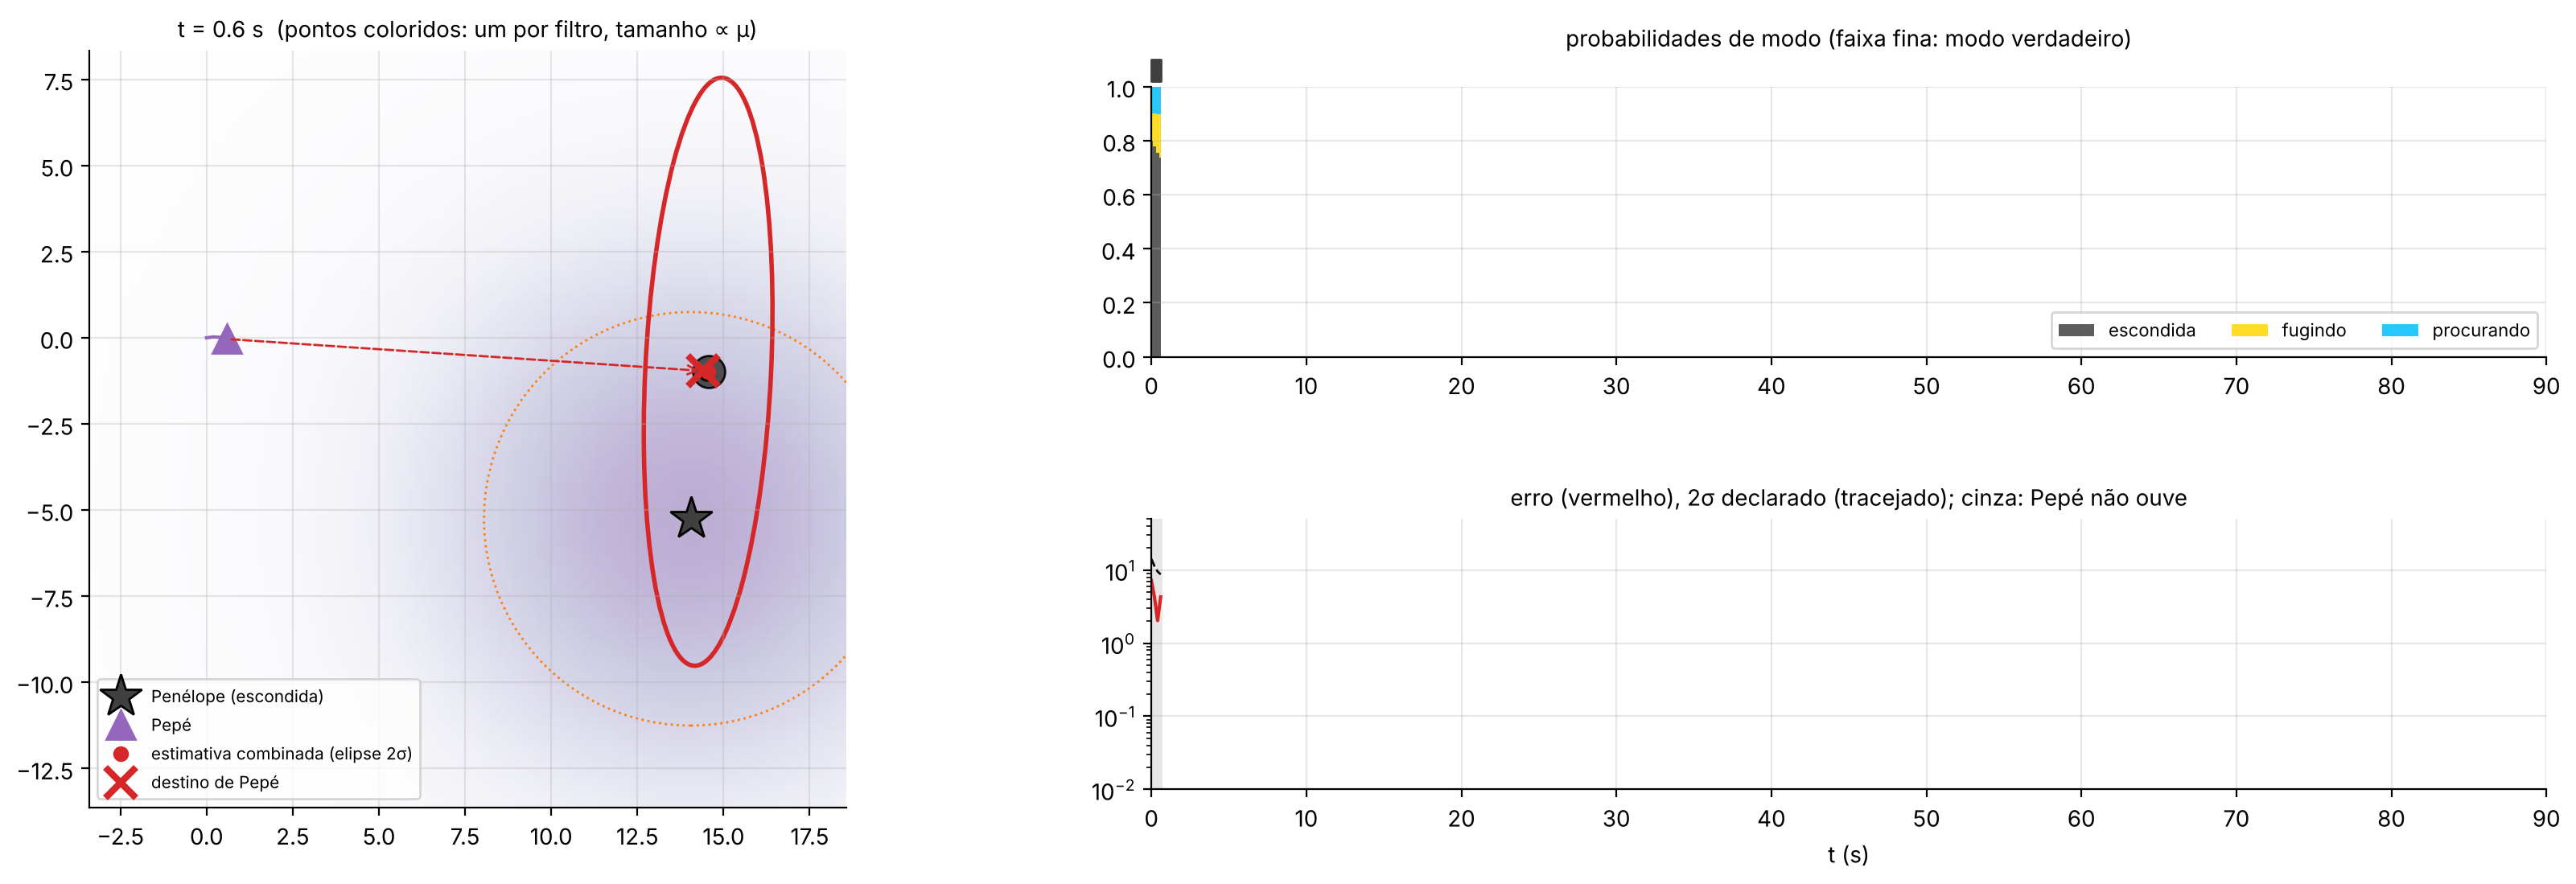

In [13]:
explica(reg, eventos["começo"])
quadro(reg, eventos["começo"], S)

### Quadro: o primeiro instante da fuga

Penélope acabou de arrancar, e Pepé **já percebeu**. Ele estava perto e ouvia o coração, então as medidas são muito precisas: um único passo de 0,6 unidade é incompatível com "parada". A log-verossimilhança do filtro "escondida" ficou cerca de 40 abaixo da do "fugindo", ou seja, $e^{-40}$ vezes menos plausível, e $\mu(\text{fugindo})$ saltou para quase 1 (a "escondida" ficou no piso de $10^{-12}$).

Observe os pesos da mistura: o filtro "fugindo" recebeu a maior parte do seu estado do filtro "escondida", inclusive a velocidade **incerta** (desvio 2) que o modelo "escondida" carrega. Foi isso que permitiu a ele estimar, já no primeiro passo, uma velocidade de quase 3 unidades/s. O destino de Pepé (×) já está bem à frente dela.

═════════  t = 12.4 s  ═════════   modo VERDADEIRO: fugindo   |  Pepé OUVE o coração
            c_j (antes da medida)  log-veross. ℓ_j  μ_j (depois) posição estimada pelo filtro j velocidade estimada pelo filtro j
escondida                   0.953          -40.729     1.000e-12                 [14.25, -5.25]                        [0.0, 0.0]
fugindo                     0.046            0.000     9.980e-01                  [14.65, -5.4]                     [2.78, -0.92]
procurando                  0.001           -2.470     1.998e-03                 [14.57, -5.47]                     [1.26, -0.61]

(ℓ_j aparece relativo ao maior: 0 = o filtro que melhor explicou a medida; −5 ≈ e⁻⁵ ≈ 150 vezes menos plausível)

pesos da mistura μ_{i|j} (linha i = de onde veio, coluna j = filtro que recebe):
            escondida  fugindo  procurando
escondida         1.0    0.719       0.000
fugindo           0.0    0.281       0.625
procurando        0.0    0.000       0.375

estimativa combinada: [14.

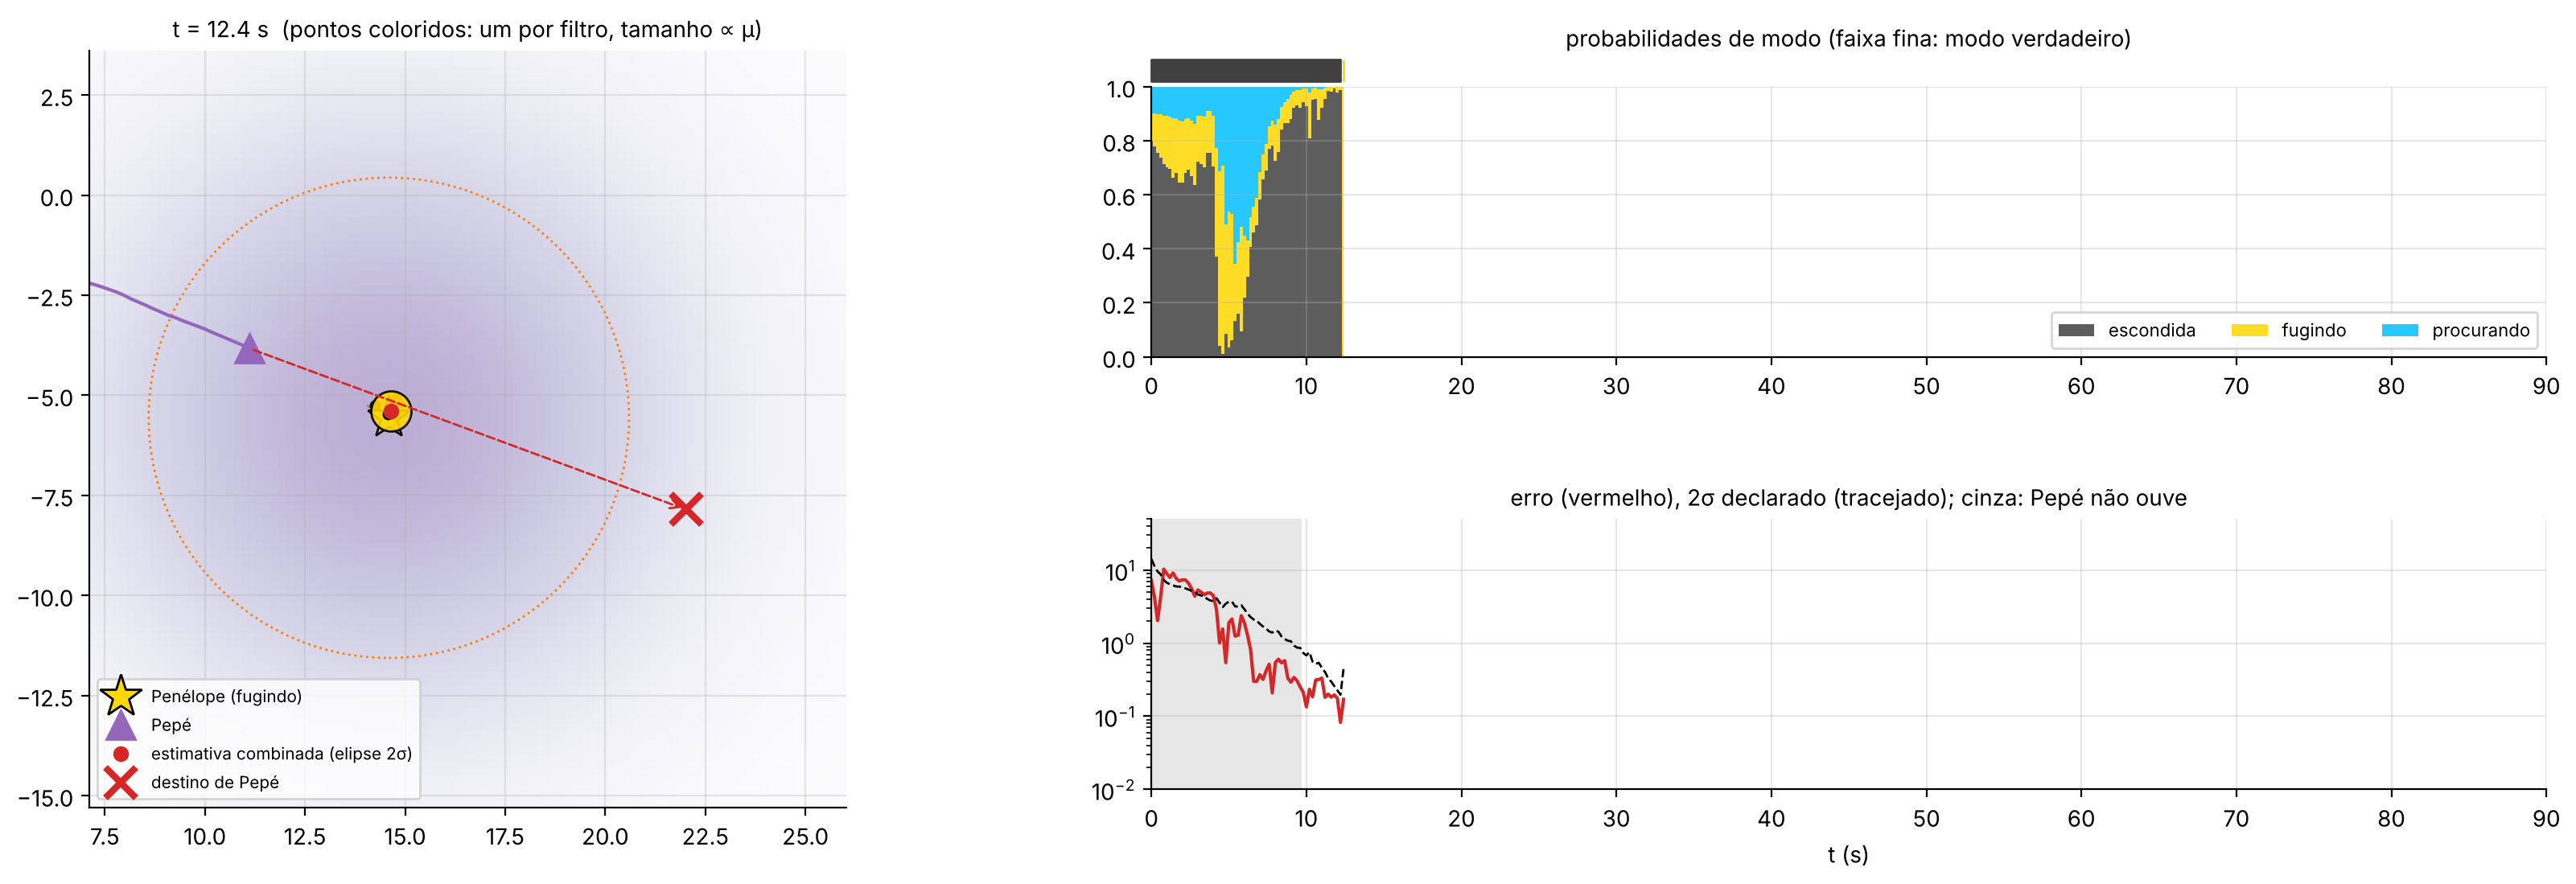

In [14]:
explica(reg, eventos["primeiro instante da fuga"])
quadro(reg, eventos["primeiro instante da fuga"], S)

### Quadro: a fuga em andamento

Pouco mais de um segundo depois, Penélope já saiu do alcance do som, e Pepé só conta com o nariz. Mesmo assim, $\mu(\text{fugindo})$ continua acima de 0,9, e a velocidade estimada se mantém: com o modelo "linha reta", poucas medidas ruidosas bastam para acompanhá-la. O destino (×) está cerca de 7 unidades à frente da estimativa: Pepé mira onde ela estará quando ele chegar, e não onde ela está.

═════════  t = 13.6 s  ═════════   modo VERDADEIRO: fugindo   |  Pepé NÃO ouve o coração
            c_j (antes da medida)  log-veross. ℓ_j  μ_j (depois) posição estimada pelo filtro j velocidade estimada pelo filtro j
escondida                   0.006           -2.641     4.746e-04                 [17.66, -6.46]                        [0.0, 0.0]
fugindo                     0.839            0.000     9.061e-01                 [18.23, -6.67]                     [2.97, -1.12]
procurando                  0.155           -0.586     9.344e-02                 [18.16, -6.71]                     [1.58, -0.75]

(ℓ_j aparece relativo ao maior: 0 = o filtro que melhor explicou a medida; −5 ≈ e⁻⁵ ≈ 150 vezes menos plausível)

pesos da mistura μ_{i|j} (linha i = de onde veio, coluna j = filtro que recebe):
            escondida  fugindo  procurando
escondida       0.328    0.000       0.000
fugindo         0.000    0.999       0.284
procurando      0.672    0.001       0.716

estimativa combinada: 

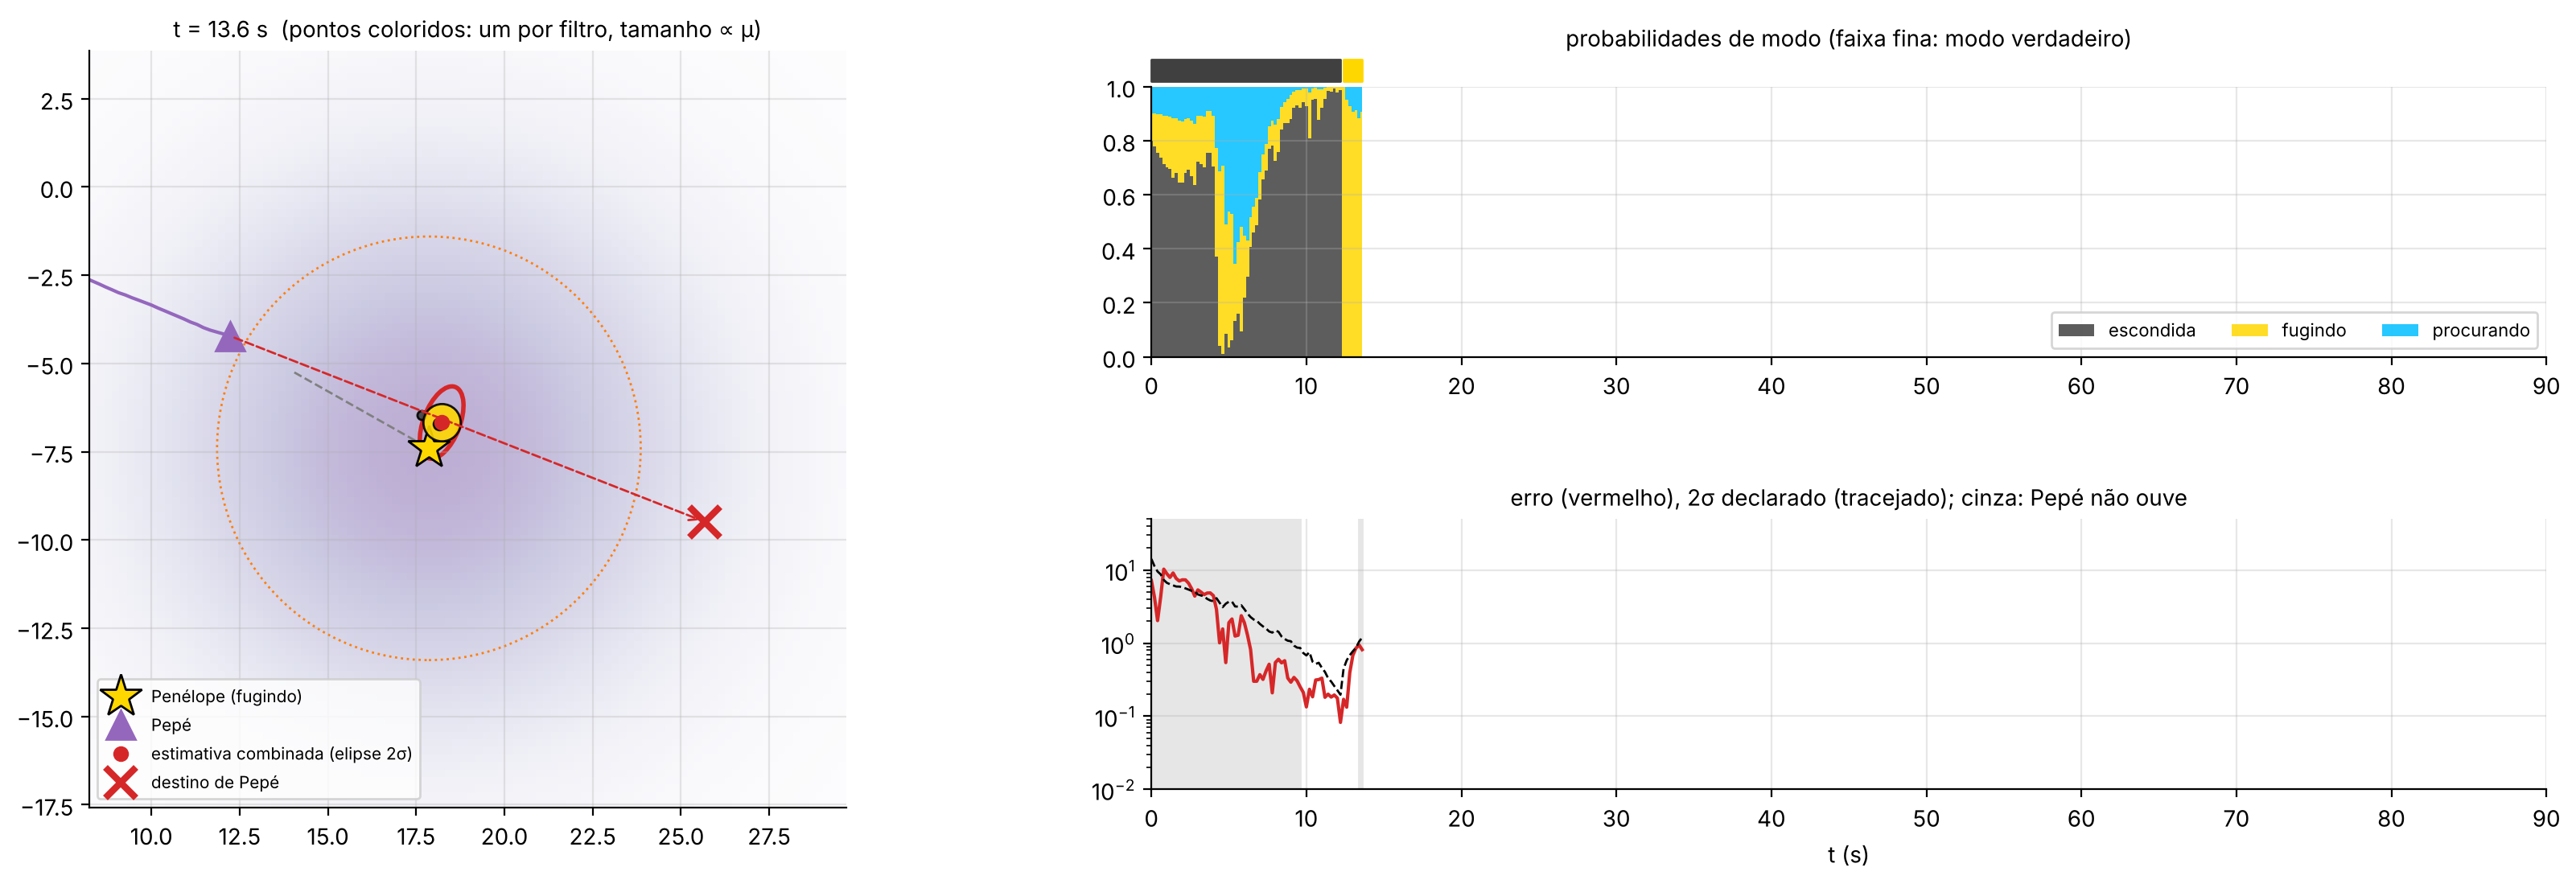

In [15]:
explica(reg, eventos["fuga em andamento"])
quadro(reg, eventos["fuga em andamento"], S)

### Quadro: ela começou a procurar

A fuga acabou e Penélope começou a dar corridinhas. Pepé ainda não percebeu: $\mu(\text{fugindo})$ continua perto de 0,8. A mudança de "linha reta" para "corridinhas em volta" leva alguns passos para aparecer nas medidas, ainda mais com Pepé longe e sem ouvir. Por isso o destino (×) ainda está à frente, na direção da fuga: Pepé está mirando um ponto aonde ela não vai.

═════════  t = 16.4 s  ═════════   modo VERDADEIRO: procurando   |  Pepé NÃO ouve o coração
            c_j (antes da medida)  log-veross. ℓ_j  μ_j (depois) posição estimada pelo filtro j velocidade estimada pelo filtro j
escondida                   0.015           -0.083         0.014                 [25.46, -9.05]                        [0.0, 0.0]
fugindo                     0.768           -0.019         0.765                  [26.28, -9.3]                      [2.7, -0.84]
procurando                  0.218            0.000         0.221                  [25.86, -9.2]                       [0.8, -0.3]

(ℓ_j aparece relativo ao maior: 0 = o filtro que melhor explicou a medida; −5 ≈ e⁻⁵ ≈ 150 vezes menos plausível)

pesos da mistura μ_{i|j} (linha i = de onde veio, coluna j = filtro que recebe):
            escondida  fugindo  procurando
escondida       0.551    0.000       0.000
fugindo         0.000    0.997       0.185
procurando      0.449    0.002       0.815

estimativa combinad

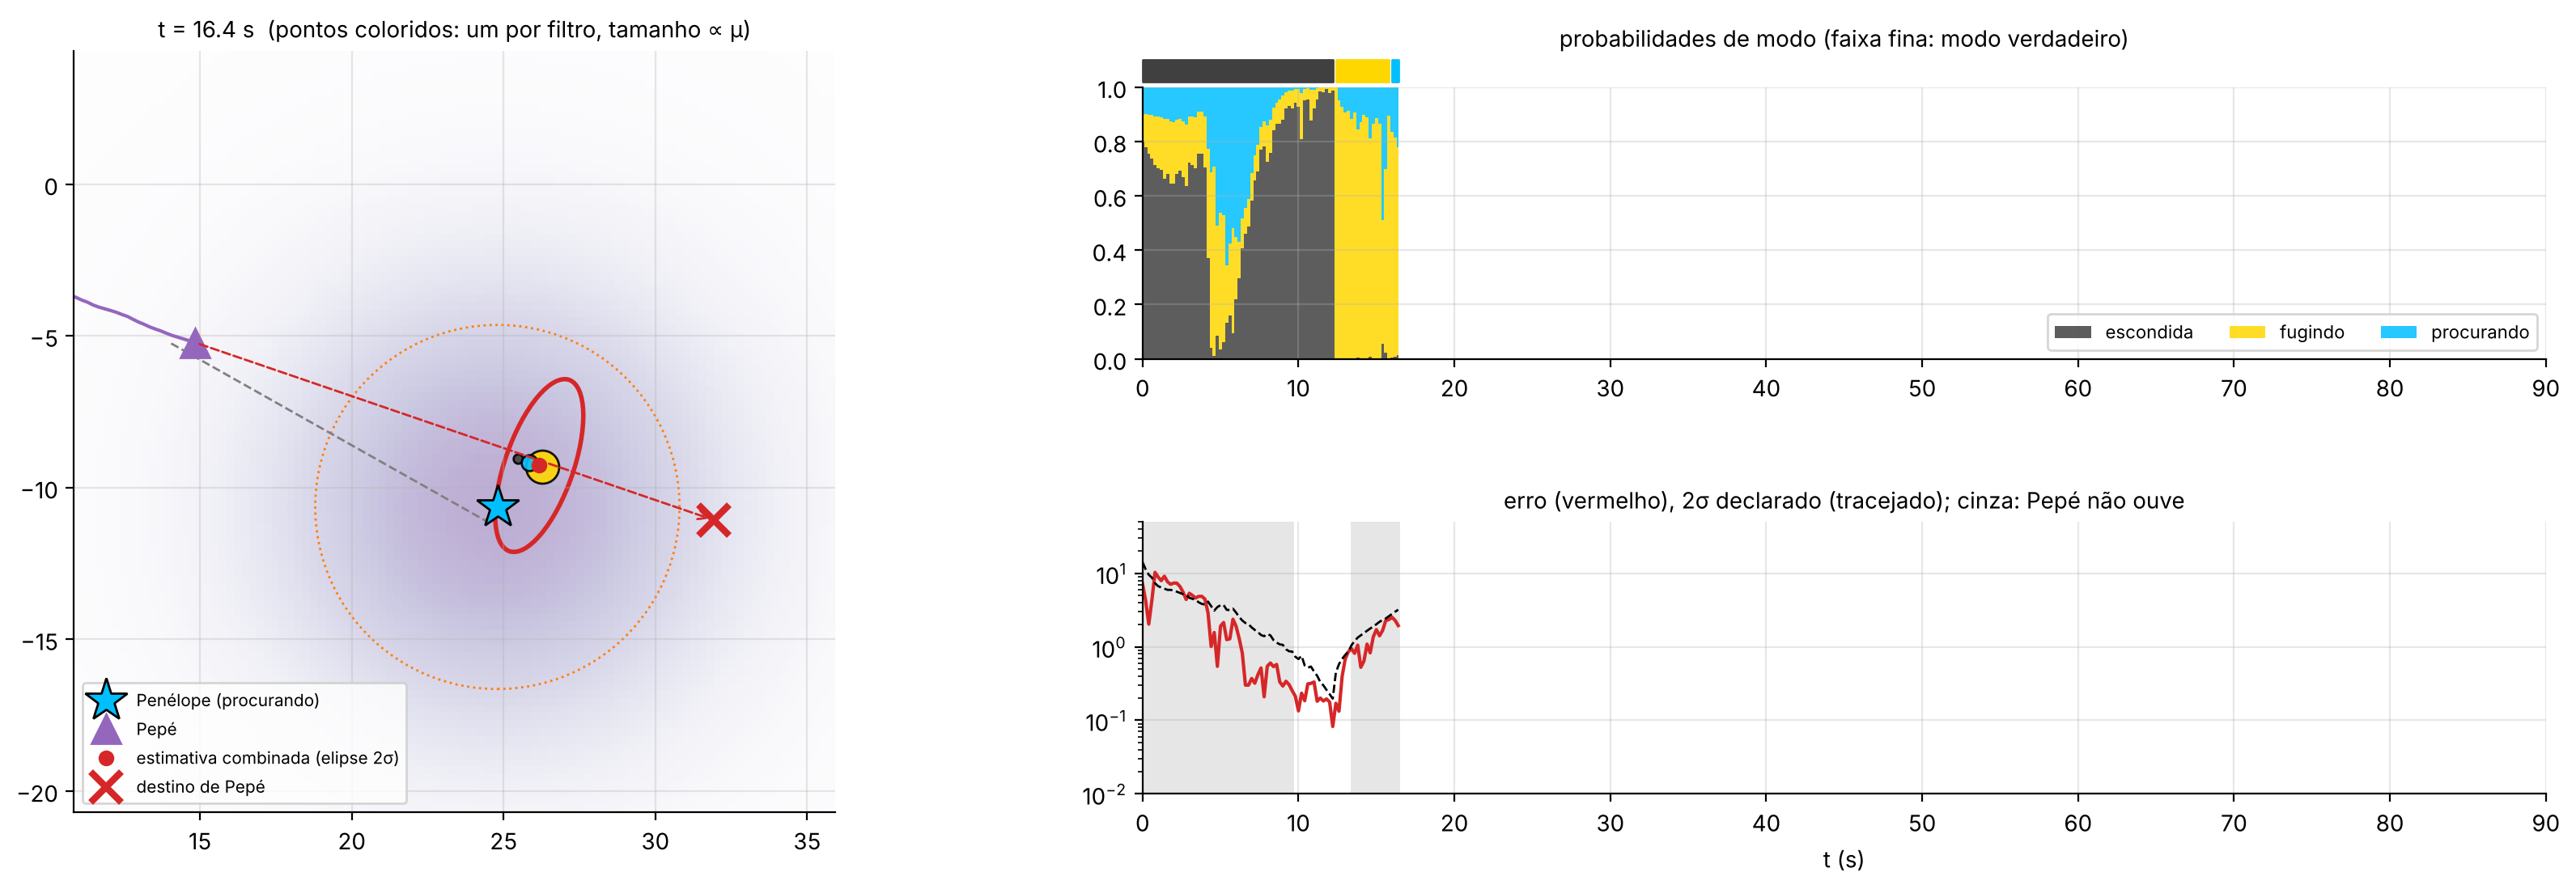

In [16]:
explica(reg, eventos["começou a procurar"])
quadro(reg, eventos["começou a procurar"], S)

### Quadro: procurando há algum tempo

Agora o filtro "procurando" (azul) explica melhor as medidas, e $\mu(\text{procurando})$ passou de 0,8. Ele aceita mudanças de direção que o "fugindo" consideraria improváveis. Compare as velocidades na tabela: o filtro "fugindo" estima uma velocidade maior que o "procurando", que "sabe" que ela não vai longe. E repare no destino (×): agora ele está praticamente **sobre** a estimativa. Pepé entendeu que ela está rodando em volta de um ponto, e que vale ir até esse ponto.

═════════  t = 18.0 s  ═════════   modo VERDADEIRO: procurando   |  Pepé NÃO ouve o coração
            c_j (antes da medida)  log-veross. ℓ_j  μ_j (depois) posição estimada pelo filtro j velocidade estimada pelo filtro j
escondida                   0.183           -0.475         0.122                  [24.3, -9.61]                        [0.0, 0.0]
fugindo                     0.068           -0.049         0.070                  [23.8, -9.63]                     [-1.49, 0.23]
procurando                  0.749            0.000         0.808                 [23.82, -9.62]                      [-0.61, 0.1]

(ℓ_j aparece relativo ao maior: 0 = o filtro que melhor explicou a medida; −5 ≈ e⁻⁵ ≈ 150 vezes menos plausível)

pesos da mistura μ_{i|j} (linha i = de onde veio, coluna j = filtro que recebe):
            escondida  fugindo  procurando
escondida       0.848    0.078       0.000
fugindo         0.000    0.820       0.004
procurando      0.152    0.102       0.996

estimativa combinad

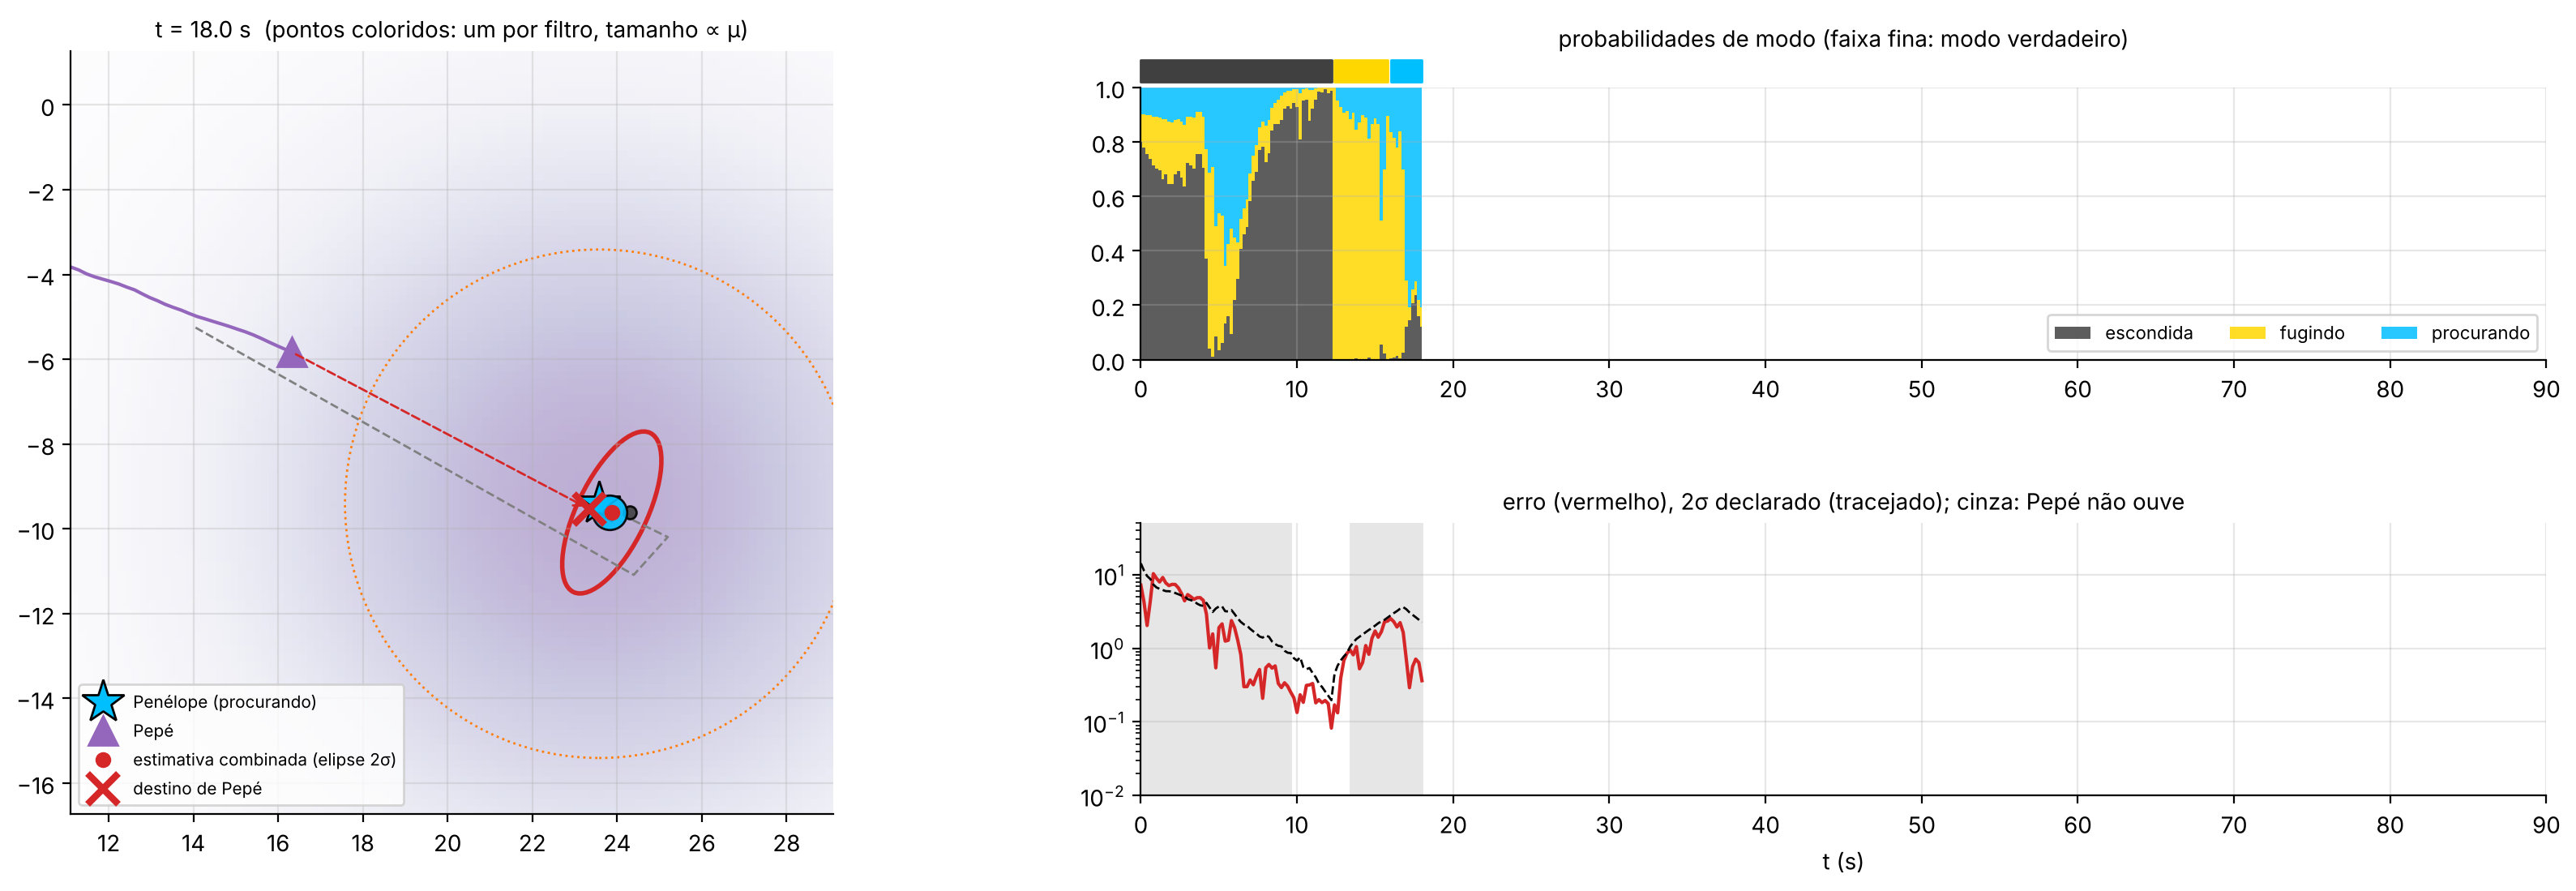

In [17]:
explica(reg, eventos["procurando há algum tempo"])
quadro(reg, eventos["procurando há algum tempo"], S)

### Quadro: escondida de novo

Ela parou, e o filtro "escondida" voltou a ser o mais provável. A partir daqui, a estimativa melhora passo a passo: com o modelo "parada", **todas** as medidas que chegam se acumulam sobre o mesmo ponto. Para estimar onde ela está, é aqui que o IMM mais ganha do modelo único, que continua admitindo que ela se mova e nunca "trava" a posição.

═════════  t = 21.6 s  ═════════   modo VERDADEIRO: escondida   |  Pepé OUVE o coração
            c_j (antes da medida)  log-veross. ℓ_j  μ_j (depois) posição estimada pelo filtro j velocidade estimada pelo filtro j
escondida                   0.506            0.000         0.661                 [24.49, -10.5]                        [0.0, 0.0]
fugindo                     0.078           -0.620         0.055                [24.41, -10.56]                     [-0.08, 0.11]
procurando                  0.416           -0.648         0.285                [24.41, -10.55]                      [0.02, 0.17]

(ℓ_j aparece relativo ao maior: 0 = o filtro que melhor explicou a medida; −5 ≈ e⁻⁵ ≈ 150 vezes menos plausível)

pesos da mistura μ_{i|j} (linha i = de onde veio, coluna j = filtro que recebe):
            escondida  fugindo  procurando
escondida        0.97    0.218       0.000
fugindo          0.00    0.733       0.007
procurando       0.03    0.050       0.993

estimativa combinada: [ 

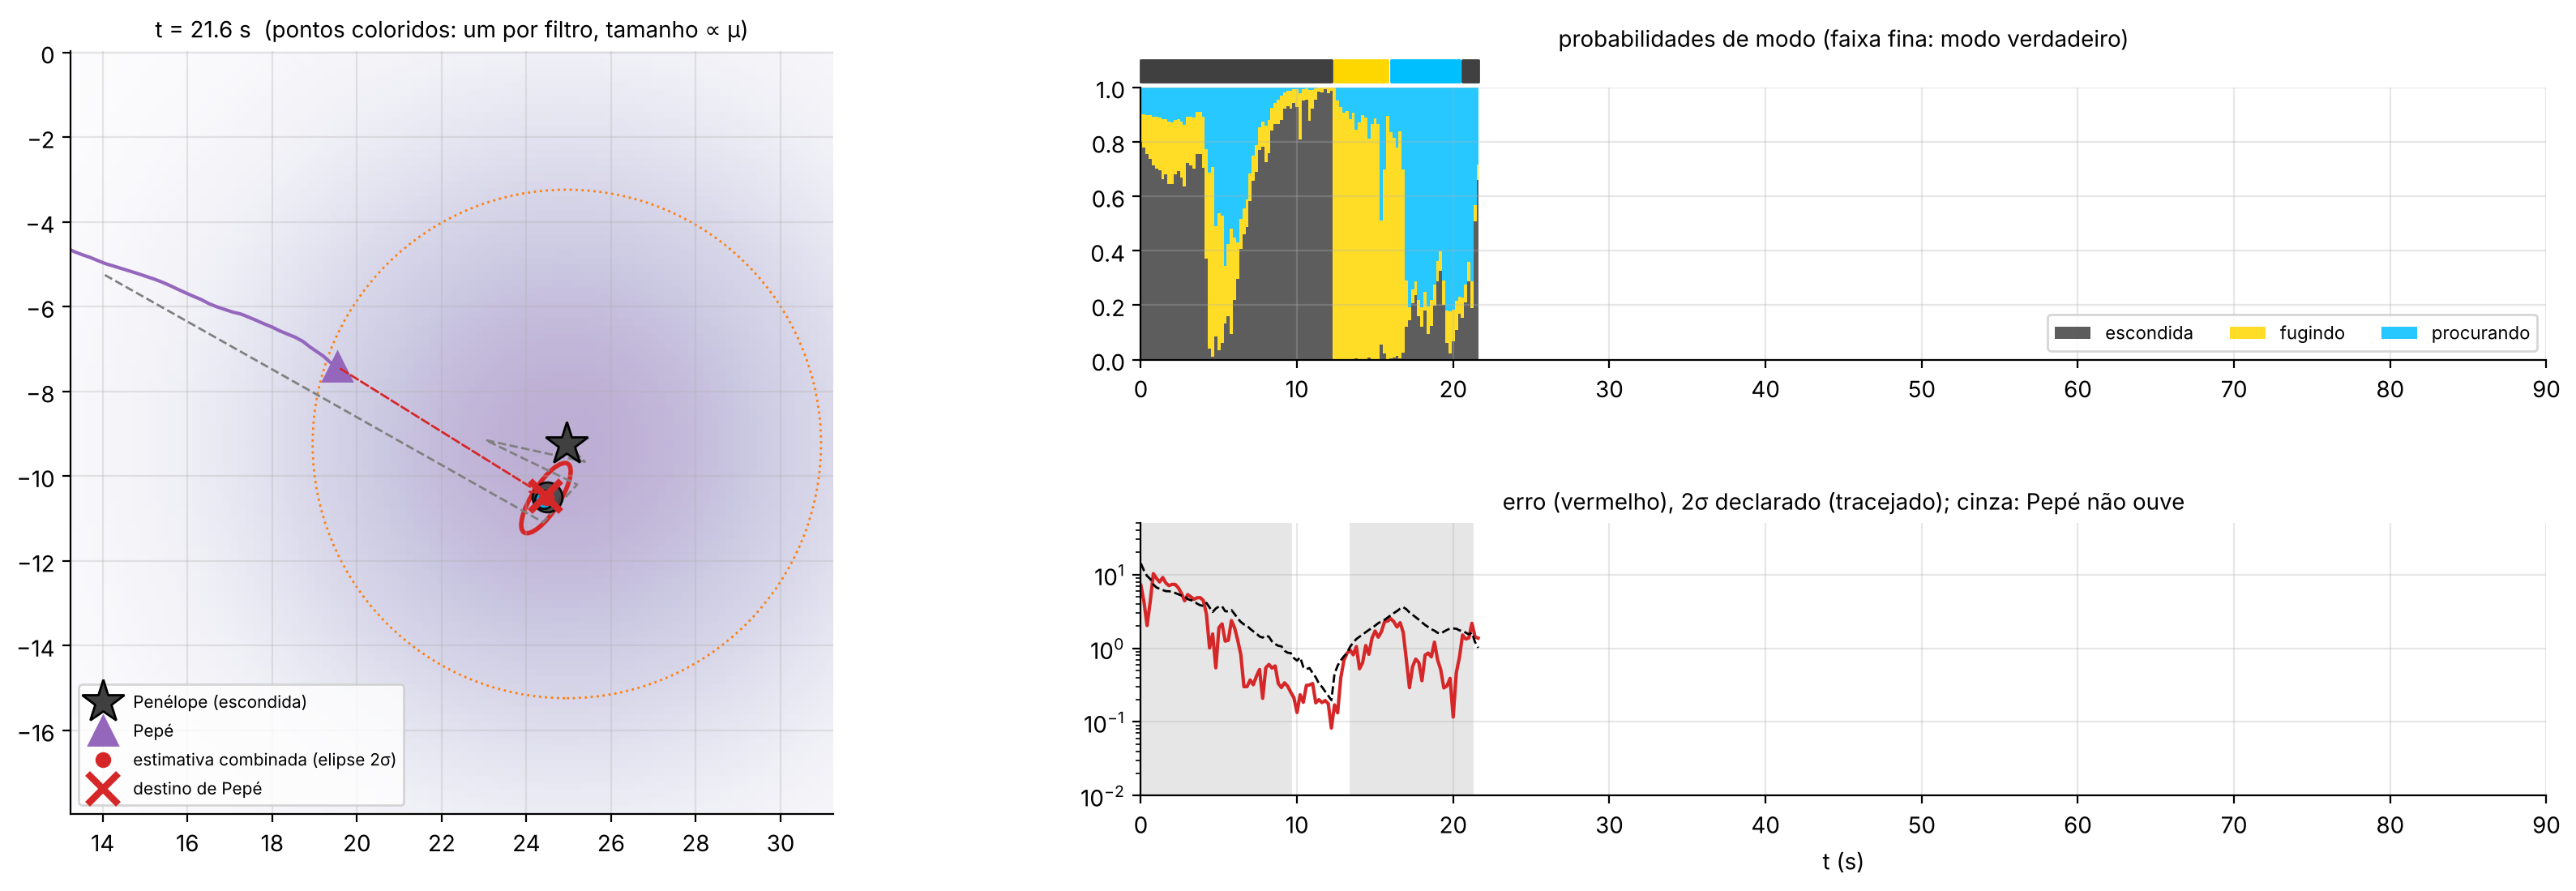

In [18]:
explica(reg, eventos["escondida de novo"])
quadro(reg, eventos["escondida de novo"], S)

## 7.2 Quanto Pepé acerta o modo?

A **matriz de confusão** compara o modo verdadeiro (linhas) com o modo mais provável segundo Pepé (colunas), em porcentagem do tempo passado em cada modo verdadeiro. Para não depender de uma só perseguição, juntamos 20 perseguições.

In [19]:
conf = np.zeros((3, 3))
for sd in range(20):
    S_c = series(simula(PEPE["IMM de 3 modos"], alvo="estara", seed=200 + sd))
    for a, b in zip(S_c["modo"], S_c["mu"].argmax(1)): conf[a, b] += 1
conf_pct = 100 * conf / conf.sum(1, keepdims=True)
print("linhas: modo verdadeiro   |   colunas: modo mais provável segundo Pepé   (% do tempo em cada modo verdadeiro)")
pd.DataFrame(conf_pct, index=[f"verdadeiro: {n}" for n in NOMES_MODOS], columns=[f"Pepé: {n}" for n in NOMES_MODOS]).round(1)

linhas: modo verdadeiro   |   colunas: modo mais provável segundo Pepé   (% do tempo em cada modo verdadeiro)


,Pepé: escondida,Pepé: fugindo,Pepé: procurando
verdadeiro: escondida,62.9,20.3,16.9
verdadeiro: fugindo,0.3,81.6,18.1
verdadeiro: procurando,9.6,17.1,73.3


**Como ler.** A diagonal mostra os acertos. "Fugindo" é o modo mais fácil de reconhecer (deslocamento grande e regular). Os outros dois são confundidos com frequência, por duas razões:

- **atraso**: logo depois de cada troca de modo, Pepé ainda acredita no modo anterior. Isso pesa sobretudo em "escondida", porque ela sempre começa logo depois de uma procura;
- **distância**: boa parte do tempo Pepé está longe, sem ouvir, e de longe, com vento, uma Penélope parada e uma dando corridinhas curtas produzem medidas muito parecidas.

---
# 8. Prever o futuro: onde o IMM realmente faz diferença

Para **estimar onde ela está agora**, sensores bons dominam, e o modelo de movimento importa pouco. A grande vantagem de um modelo melhor aparece na **previsão**: onde ela estará daqui a 2 ou 4 segundos?

Medimos isso diretamente. Em vários instantes de várias perseguições, cada Pepé prevê a posição de Penélope $H$ passos à frente (função `preve_adiante`, sem medidas). Comparamos com onde ela **realmente** estava $H$ passos depois, separando os casos pelo modo verdadeiro no instante da previsão.

Para comparar só o **modelo**, todos os Pepés seguem a mesma regra de perseguição ("mira onde está"), e cada um prevê com o seu próprio conjunto de filtros.

In [20]:
linhas = []
for nome in ["modelo único (Parte 1)", "IMM de 2 modos", "IMM de 3 modos"]:
    pep = PEPE[nome]
    for H_seg in [2.0, 4.0]:
        H = int(round(H_seg / DT)); erros = {j: [] for j in range(3)}
        for sd in range(12):
            rg = simula(pep, alvo="esta", seed=300 + sd, guarda_filtros=True)
            for k in range(50, len(rg) - H, 3):
                r = rg[k]
                prev, _ = preve_adiante(r["mu"], r["ms"], r["Ps"], pep["modelos"], pep["Pi"], H)
                erros[r["modo"]].append(np.linalg.norm(prev - rg[k + H]["p"]))
        linhas.append({"Pepé": nome, "horizonte (s)": H_seg,
                       **{f"erro mediano se agora está {NOMES_MODOS[j]}": np.median(erros[j]) for j in range(3)}})
tab_prev = pd.DataFrame(linhas).set_index(["horizonte (s)", "Pepé"]).sort_index()
tab_prev

erro mediano se agora está escondida  \
horizonte (s) Pepé                                                           
2.0           IMM de 2 modos                                         2.854   
              IMM de 3 modos                                         2.780   
              modelo único (Parte 1)                                 2.318   
4.0           IMM de 2 modos                                         8.232   
              IMM de 3 modos                                         8.235   
              modelo único (Parte 1)                                 6.558   

                                      erro mediano se agora está fugindo  \
horizonte (s) Pepé                                                         
2.0           IMM de 2 modos                                       2.008   
              IMM de 3 modos                                       2.373   
              modelo único (Parte 1)                               1.996   
4.0           IMM de 2 modos                                       3.740   
              IMM de 3 modos                                       4.289   
              modelo único (Parte 1)                               6.543   

                                      erro mediano se agora está procurando  
horizonte (s) Pepé                                                           
2.0           IMM de 2 modos                                          2.390  
              IMM de 3 modos                                          2.163  
              modelo único (Parte 1)                                  3.527  
4.0           IMM de 2 modos                                          3.370  
              IMM de 3 modos                                          3.161  
              modelo único (Parte 1)                                  6.102

**O que observar.**

- **Durante a fuga**, o modelo único extrapola a linha reta, mas as fugas acabam. Com horizonte de 4 s ele erra muito mais que os IMMs, que sabem, pela cadeia de Markov, que a fuga tende a terminar.
- **Durante a procura**, o IMM de 3 modos é o melhor: só ele tem um modelo em que ela "fica rodando" num lugar.
- **Quando ela está escondida**, todos erram bastante, e o modelo único chega a errar **menos** que os IMMs. A próxima fuga começa porque **Pepé chega perto**, e nenhum dos modelos sabe disso: para eles, a fuga começa por sorteio. O IMM reserva alguma probabilidade para "ela vai fugir", e o filtro "fugindo" extrapola por 4 s as pequenas velocidades, ruidosas, que estima mesmo com ela parada; isso puxa a previsão para o lado errado. É a limitação do modelo de Markov homogêneo, e o tema do exercício 2.

Isso responde à pergunta "onde ela estará?": **a cadeia de Markov é o que dá a Pepé uma noção de futuro**. Um único Kalman só sabe extrapolar o presente.

---
# 9. Comparação estatística: mundos de 2 e de 3 modos

Agora comparamos todas as combinações:

- **3 Pepés**: modelo único, IMM de 2 modos, IMM de 3 modos;
- **2 alvos**: onde ela está × onde ela estará;
- **2 mundos**: Penélope com 2 ou com 3 modos.

São 24 perseguições de 90 s por combinação. As métricas:

| métrica | o que mede |
|---|---|
| **erro mediano** | quão bem Pepé sabe onde ela está |
| **tempo perdido** | % do tempo com erro maior que 10 |
| **dentro da elipse 2σ** | honestidade do filtro (ideal ≈ 86%) |
| **encontros** | quantas vezes, em média, Pepé chegou perto o bastante para fazê-la fugir: o sucesso da perseguição |
| **acerto de modo** | % do tempo em que o modo mais provável é o verdadeiro. No mundo de 3 modos, o IMM de 2 modos conta como acerto chamar "procurando" de "fugindo" |

A célula leva de 1 a 2 minutos.

In [21]:
def avalia(pep, alvo, mundo, n=24):
    E, PERD, CONS, ENC, AC = [], [], [], [], []
    M = len(pep["modelos"])
    for sd in range(n):
        S_ = series(simula(pep, alvo=alvo, seed=500 + sd, modos_do_mundo=mundo))
        E.append(np.median(S_["erro"])); PERD.append(np.mean(S_["erro"] > 10)); CONS.append(np.mean(S_["nees"] <= 4.0))
        ENC.append(np.sum((S_["modo"][1:] == FUG) & (S_["modo"][:-1] != FUG)))
        if M == 3: AC.append(np.mean(S_["mu"].argmax(1) == S_["modo"]))
        if M == 2: AC.append(np.mean(S_["mu"].argmax(1) == np.where(S_["modo"] == ESC, 0, 1)))
    return {"erro mediano": np.median(E), "tempo perdido (%)": 100 * np.mean(PERD),
            "dentro da elipse 2σ (%)": 100 * np.mean(CONS), "encontros": np.mean(ENC),
            "acerto de modo (%)": 100 * np.mean(AC) if AC else np.nan}

linhas = []
for mundo in [2, 3]:
    for nome, pep in PEPE.items():
        if mundo == 2 and nome == "IMM de 3 modos": continue
        for alvo, txt in [("esta", "está"), ("estara", "estará")]:
            linhas.append({"mundo": f"{mundo} modos", "Pepé": nome, "mira onde ela": txt, **avalia(pep, alvo, mundo)})
tabela = pd.DataFrame(linhas).set_index(["mundo", "Pepé", "mira onde ela"])
tabela

erro mediano  tempo perdido (%)  \
mundo   Pepé                   mira onde ela                                    
2 modos modelo único (Parte 1) está                  0.519              5.231   
                               estará                0.477              5.278   
        IMM de 2 modos         está                  0.374              5.583   
                               estará                0.340              5.361   
3 modos modelo único (Parte 1) está                  0.481              5.213   
                               estará                0.512              5.278   
        IMM de 2 modos         está                  0.471              5.583   
                               estará                0.426              5.361   
        IMM de 3 modos         está                  0.443              5.593   
                               estará                0.439              5.556   

                                              dentro da elipse 2σ (%)  \
mundo   Pepé                   mira onde ela                            
2 modos modelo único (Parte 1) está                            84.111   
                               estará                          84.611   
        IMM de 2 modos         está                            85.750   
                               estará                          85.926   
3 modos modelo único (Parte 1) está                            83.380   
                               estará                          83.463   
        IMM de 2 modos         está                            80.148   
                               estará                          80.954   
        IMM de 3 modos         está                            83.509   
                               estará                          83.352   

                                              encontros  acerto de modo (%)  
mundo   Pepé                   mira onde ela                                 
2 modos modelo único (Parte 1) está               7.375                 NaN  
                               estará             7.292                 NaN  
        IMM de 2 modos         está               7.417              91.639  
                               estará             7.625              91.806  
3 modos modelo único (Parte 1) está               7.583                 NaN  
                               estará             6.708                 NaN  
        IMM de 2 modos         está               7.417              78.204  
                               estará             7.583              78.315  
        IMM de 3 modos         está               7.458              76.472  
                               estará             7.625              76.620

**Como ler a tabela.**

- **Erro mediano.** No mundo de 2 modos, o IMM erra cerca de 30% menos que o modelo único: com o modelo "parada", as medidas se acumulam sobre um ponto fixo quando ela está escondida. No mundo de 3 modos o ganho é pequeno, porque ela passa menos tempo parada e a procura é difícil para todos.
- **Honestidade.** No mundo de 3 modos, o IMM de 2 modos fica menos consistente (a elipse acerta menos): ele não tem um modelo para a procura e fica confiante demais nesses momentos. O IMM de 3 modos recupera a consistência.
- **Está × estará.** O número de encontros não muda de forma consistente (fica entre 6,7 e 7,6 em todas as linhas, dentro do ruído de 24 perseguições). Penélope corre 2,5 a 3,5 vezes mais rápido que Pepé e só para quando quer; quem decide quando há um encontro é ela. As previsões em si melhoram muito com o IMM (seção 8), mas o gargalo da perseguição é a velocidade de Pepé, não a previsão.
- **Acerto de modo.** No mundo de 2 modos, o IMM de 2 modos acerta cerca de 90% do tempo. No mundo de 3 modos, os dois IMMs ficam perto de 77%. O de 2 modos é avaliado com uma régua mais fácil (chamar "procurando" de "fugindo" conta como acerto), e mesmo assim não vai melhor.
- **Tempo perdido.** Os poucos por cento de tempo perdido, iguais para todos, vêm de perseguições em que uma fuga longa a leva para além do alcance do cheiro. Aí nenhum modelo ajuda: não há o que medir.

Esses números são de 24 perseguições: diferenças pequenas (por exemplo, meio encontro) estão dentro do ruído da amostra.

---
# 10. Resumo

| conceito | onde aparece | leitura em aprendizado de máquina |
|---|---|---|
| modo de comportamento | escondida, fugindo, procurando | variável **latente discreta** |
| matriz $\Pi$ | durações médias imaginadas | ***prior*** sobre as sequências de modos |
| um Kalman por modo | três pares $(F_j,Q_j)$ | **mistura de especialistas**: cada um especializado num regime |
| verossimilhança $L_j$ | etapa (3) | quão bem cada especialista explica o dado |
| $\mu_j\propto c_j L_j$ | etapa (4) | o *forward* do HMM; a **porta** (*gating*) que pesa os especialistas |
| mistura | etapa (1) | compartilhar informação entre especialistas antes de cada passo |
| prever adiante | seção 6 | usar o modelo generativo para **simular** o futuro |

A frase para levar: **o IMM é um HMM cujas "emissões" são filtros de Kalman**. As duas trilhas do primeiro notebook, a discreta e a contínua, viram uma coisa só.

## Exercícios

1. **Pepé indeciso.** Troque as durações médias da matriz $\Pi$ por valores muito curtos (1 s) e muito longos (30 s). O que acontece com o acerto de modo e com o atraso para perceber uma fuga?
2. **Pepé que sabe que a assusta.** A fuga começa quando **ele** chega perto. Faça a probabilidade de "escondida → fugindo" depender da distância estimada $\hat d$, por exemplo $\Pi_{01}(\hat d)=0{,}5\,\sigma\big((3-\hat d)/0{,}5\big)$, onde $\sigma$ é a logística, e recalcule $\Pi$ a cada passo. A previsão da seção 8, para ela "escondida", melhora? (Isso é uma **cadeia de Markov não homogênea**, com transições que dependem de uma covariável.)
3. **Aprender $\Pi$ com os dados.** Guarde as probabilidades $\mu_t$ e as probabilidades conjuntas de pares de modos ao longo de várias perseguições, e reestime $\Pi$ pelo passo M do Baum–Welch (contagens esperadas normalizadas). As durações aprendidas ficam parecidas com as do mundo? Por que não iguais? (Dica: a duração da fase "escondida" depende de Pepé.)
4. **Quarto modo.** Acrescente ao mundo um modo "provocando": Penélope se aproxima de Pepé por um instante. Que par $(F,Q)$ você daria a esse modo? Como você mudaria $\Pi$?
5. **Sem som.** Repita a seção 9 só com o nariz (Fase 2 da Parte 1). O IMM passa a fazer mais diferença ou menos? Por quê?
6. **Vídeo.** Adapte o notebook gerador de vídeo da Parte 1 para mostrar o IMM: um ponto por filtro, com tamanho proporcional a $\mu_j$, e uma barra com as probabilidades de modo.

## Referências

- H. A. P. Blom, Y. Bar-Shalom. The interacting multiple model algorithm for systems with Markovian switching coefficients. *IEEE Trans. Automatic Control* 33(8), 1988.
- Y. Bar-Shalom, X. R. Li, T. Kirubarajan. *Estimation with Applications to Tracking and Navigation*. Wiley, 2001 (capítulo 11, sobre IMM).
- R. A. Singer. Estimating optimal tracking filter performance for manned maneuvering targets. *IEEE Trans. Aerospace and Electronic Systems* 6(4), 1970.
- B. M. Bell, F. W. Cathey. The iterated Kalman filter update as a Gauss–Newton method. *IEEE Trans. Automatic Control* 38(2), 1993.